# Proyecto de Datos 2: satisfacción de pasajeros


## Objetivo y ruta del análisis

El usuario propuesto es el equipo de experiencia del cliente de una aerolínea. Buscamos apoyar el diagnóstico posterior al viaje y seleccionar servicios para investigar en Eco, Eco Plus y Business. Si la encuesta ya contiene satisfacción, la predicción no reemplaza esa respuesta: es una herramienta de análisis de patrones.

Comparamos una referencia constante y cuatro clasificadores con pipelines y una partición estratificada reproducible. ROC AUC permite comparar discriminación sin fijar umbral; 0,5 se usa como referencia descriptiva para los errores, no como umbral económico optimizado. El criterio mínimo técnico es superar la referencia constante; utilidad comercial requiere un piloto, no solo buen AUC. No se impone un objetivo numérico retrospectivo.

La elección de modelos cubre una referencia lineal y alternativas no lineales. No añadimos GPT-2 ni PCA: priorizamos una solución reproducible e interpretable para el objetivo del trabajo. No se hizo búsqueda exhaustiva de hiperparámetros. La escala 0–5 se conserva según la definición confirmada por el equipo.

Fuente: [Kaggle Playground S6E10](https://www.kaggle.com/competitions/playground-series-s6e10). Los datos de competición son una demostración; no permiten estimar directamente retorno económico en una aerolínea real. No hay fechas ni identificador verificable de persona que permitan validación temporal o por pasajero. La exploración previa utilizó todo train y se declara como limitación.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

from pathlib import Path
FIG_DIR = Path('figuras_presentacion')
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'font.size': 11})
_show_original = plt.show
_fig_contador = 0
_cell_tag = 'figura'
def guardar_y_mostrar(*args, **kwargs):
    global _fig_contador
    for numero in plt.get_fignums():
        figura = plt.figure(numero)
        _fig_contador += 1
        nombre = f'{_cell_tag}_{_fig_contador:02d}'
        figura.savefig(FIG_DIR / f'{nombre}.png', bbox_inches='tight')
        figura.savefig(FIG_DIR / f'{nombre}.svg', bbox_inches='tight')
    _show_original(*args, **kwargs)
    plt.close('all')
plt.show = guardar_y_mostrar


## 1. Carga de datos

In [2]:
_cell_tag = 'seccion_04'
# Carga de dataset Train y Test

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

# Mostrar todo el contenido de las columnas y ajustar el ancho de pantalla
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)

# Ahora ejecutas tu visualización
train.head(10)
#test.head(10)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False
5,5,34,584,4,4,4,4,1,4,1,...,4,4,1,0,0.0,Female,disloyal Customer,Business travel,Business,False
6,6,36,1763,5,5,5,5,3,4,4,...,4,3,3,0,0.0,Female,Loyal Customer,Business travel,Business,True
7,7,57,861,1,3,1,3,4,4,4,...,5,4,2,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
8,8,60,581,3,3,3,3,5,4,5,...,4,4,5,0,0.0,Female,Loyal Customer,Business travel,Business,True
9,9,44,588,3,3,2,2,2,3,2,...,4,1,2,0,0.0,Female,disloyal Customer,Business travel,Eco,False


## 2. Diagnóstico inicial
Se realiza antes de imputar para conservar evidencia de los valores faltantes. Se excluye `id` al buscar filas repetidas.

In [3]:
_cell_tag = 'seccion_06'
train_antes_limpieza = train.copy(deep=True)
test_antes_limpieza = test.copy(deep=True)
resumen_calidad = pd.DataFrame({nombre: {
    'Filas': len(df), 'Columnas': df.shape[1],
    'Celdas nulas': int(df.isna().sum().sum()),
    'Duplicados sin id': int(df.drop(columns='id').duplicated().sum()),
    'ID único': df['id'].is_unique
} for nombre, df in [('Train', train), ('Test', test)]}).T
display(resumen_calidad)
resumen_nulos = pd.DataFrame({
    'Nulos Train': train.isna().sum(),
    '% Train': train.isna().mean() * 100,
    'Nulos Test': test.isna().sum().reindex(train.columns),
    '% Test': test.isna().mean().reindex(train.columns) * 100
})
display(resumen_nulos.loc[resumen_nulos[['Nulos Train','Nulos Test']].fillna(0).gt(0).any(axis=1)].round(4))
display(train[['Age','Flight Distance','Departure Delay in Minutes','Arrival Delay in Minutes']].describe().round(2))


,Filas,Columnas,Celdas nulas,Duplicados sin id,ID único
Train,699635,23,292,0,True
Test,299844,22,130,0,True


,Nulos Train,% Train,Nulos Test,% Test
Arrival Delay in Minutes,292,0.0417,130.0,0.0434


,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.0,699635.00,699635.00,699343.00
mean,39.0,1353.78,1.18,1.13
std,13.8,954.42,5.98,5.75
min,7.0,67.00,0.00,0.00
25%,27.0,631.00,0.00,0.00
50%,40.0,954.00,0.00,0.00
75%,50.0,1814.00,0.00,0.00
max,85.0,4983.00,489.00,491.00


**Interpretación:** entrenamiento contiene 699.635 registros y test 299.844. El objetivo solo está en entrenamiento. No hay filas duplicadas completas al excluir `id`; esto no comprueba que sean personas distintas. Solo el retraso de llegada tiene nulos: 292 en train y 130 en test (cerca del 0,04 %).

## 3. Validaciones originales

In [4]:
_cell_tag = 'seccion_09'
# Limpieza


ordinal_cols = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Cleanliness'
]

# 1. Verificar que todas las columnas sean de tipo entero
son_enteros = (train[ordinal_cols].dtypes == 'int64').all()

# 2. Verificar que todos los valores sean únicamente 0, 1, 2, 3, 4 o 5
en_rango = train[ordinal_cols].isin(range(0, 6)).all().all()

print(f"¿Son tipo entero?: {son_enteros}")
print(f"¿Todos los datos son enteros entre 0 y 5?: {en_rango}")

¿Son tipo entero?: True
¿Todos los datos son enteros entre 0 y 5?: True


In [5]:
_cell_tag = 'seccion_10'
num_cols = ['Age', 'Flight Distance']

# 1. Verificar que sean enteros y sin nulos
son_enteros = (train[num_cols].dtypes == 'int64').all()
sin_nulos = train[num_cols].isnull().sum().sum() == 0

# 2. Verificar que todos los valores sean estrictamente positivos (> 0)
son_positivos_train = (train[num_cols] > 0).all().all()
son_positivos_test = (test[num_cols] > 0).all().all()

print(f"¿Son tipo entero?: {son_enteros}")
print(f"¿Sin valores nulos?: {sin_nulos}")
print(f"¿Todos mayores a 0 en Train?: {son_positivos_train}")
print(f"¿Todos mayores a 0 en Test?:  {son_positivos_test}")

¿Son tipo entero?: True
¿Sin valores nulos?: True
¿Todos mayores a 0 en Train?: True
¿Todos mayores a 0 en Test?:  True


In [6]:
_cell_tag = 'seccion_11'
cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

for col in cat_cols:
    df_summary = pd.DataFrame({
        'Train Count': train[col].value_counts(dropna=False),
        'Train %': (train[col].value_counts(normalize=True, dropna=False) * 100).round(2),
        'Test Count': test[col].value_counts(dropna=False),
        'Test %': (test[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    })
    display(df_summary)

,Train Count,Train %,Test Count,Test %
Gender,,,,
Male,351683,50.27,150261,50.11
Female,347952,49.73,149583,49.89


,Train Count,Train %,Test Count,Test %
Customer Type,,,,
Loyal Customer,576990,82.47,247708,82.61
disloyal Customer,122645,17.53,52136,17.39


,Train Count,Train %,Test Count,Test %
Type of Travel,,,,
Business travel,497441,71.1,213141,71.08
Personal Travel,202194,28.9,86703,28.92


,Train Count,Train %,Test Count,Test %
Class,,,,
Business,342212,48.91,146626,48.90
Eco,327404,46.80,140220,46.76
Eco Plus,30019,4.29,12998,4.33


### 3.1. Justificación de la imputación
Antes de sustituir faltantes, se estudia la relación entre retrasos en registros completos. La coincidencia puede estar dominada por vuelos sin retraso; por eso también se muestra el subconjunto con algún retraso.

In [7]:
_cell_tag = 'seccion_13'
cols_retraso = ['Departure Delay in Minutes','Arrival Delay in Minutes']
completos = train_antes_limpieza[cols_retraso].dropna()
diferencia = completos.iloc[:, 1] - completos.iloc[:, 0]
con_retraso = completos.gt(0).any(axis=1)
display(pd.Series({
    'Correlación entre retrasos': completos.corr().iloc[0,1],
    '% de coincidencia exacta': diferencia.eq(0).mean()*100,
    'Diferencia absoluta media (min)': diferencia.abs().mean(),
    'Registros con algún retraso': int(con_retraso.sum()),
    '% coincidencia con algún retraso': diferencia[con_retraso].eq(0).mean()*100,
    'Llegadas con fracciones de minuto': int(completos.iloc[:,1].mod(1).ne(0).sum())
}).to_frame('Resultado').round(4))


,Resultado
Correlación entre retrasos,0.8420
% de coincidencia exacta,86.8966
Diferencia absoluta media (min),0.8915
Registros con algún retraso,93088.0000
% coincidencia con algún retraso,1.5577
Llegadas con fracciones de minuto,0.0000


**Decisión:** se conserva la imputación original usando el retraso de salida. La correlación es aproximadamente 0,842 y ambos retrasos coinciden en 86,90 % de los registros completos; es una aproximación razonable para pocos faltantes, no una identidad entre variables. No hay fracciones de minuto observadas que se pierdan al convertir a entero. Más adelante se podrá comparar con una imputación por mediana ajustada solo en entrenamiento.

In [8]:
_cell_tag = 'seccion_15'
# 1. Imputar nulos en 'Arrival Delay in Minutes' usando 'Departure Delay in Minutes'
train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(train['Departure Delay in Minutes']).astype(int)
test['Arrival Delay in Minutes'] = test['Arrival Delay in Minutes'].fillna(test['Departure Delay in Minutes']).astype(int)

# 2. Confirmación final de nulos en ambos datasets
print(f"Nulos restantes en Train: {train.isnull().sum().sum()}")
print(f"Nulos restantes en Test:  {test.isnull().sum().sum()}")

Nulos restantes en Train: 0
Nulos restantes en Test:  0


## 4. Exploración por género
Se conservan los gráficos originales. Precaución: sus colores pueden cambiar de significado entre paneles; leer las leyendas. En las figuras añadidas se fijan los colores. Las cantidades absolutas deben interpretarse considerando el tamaño de cada grupo.

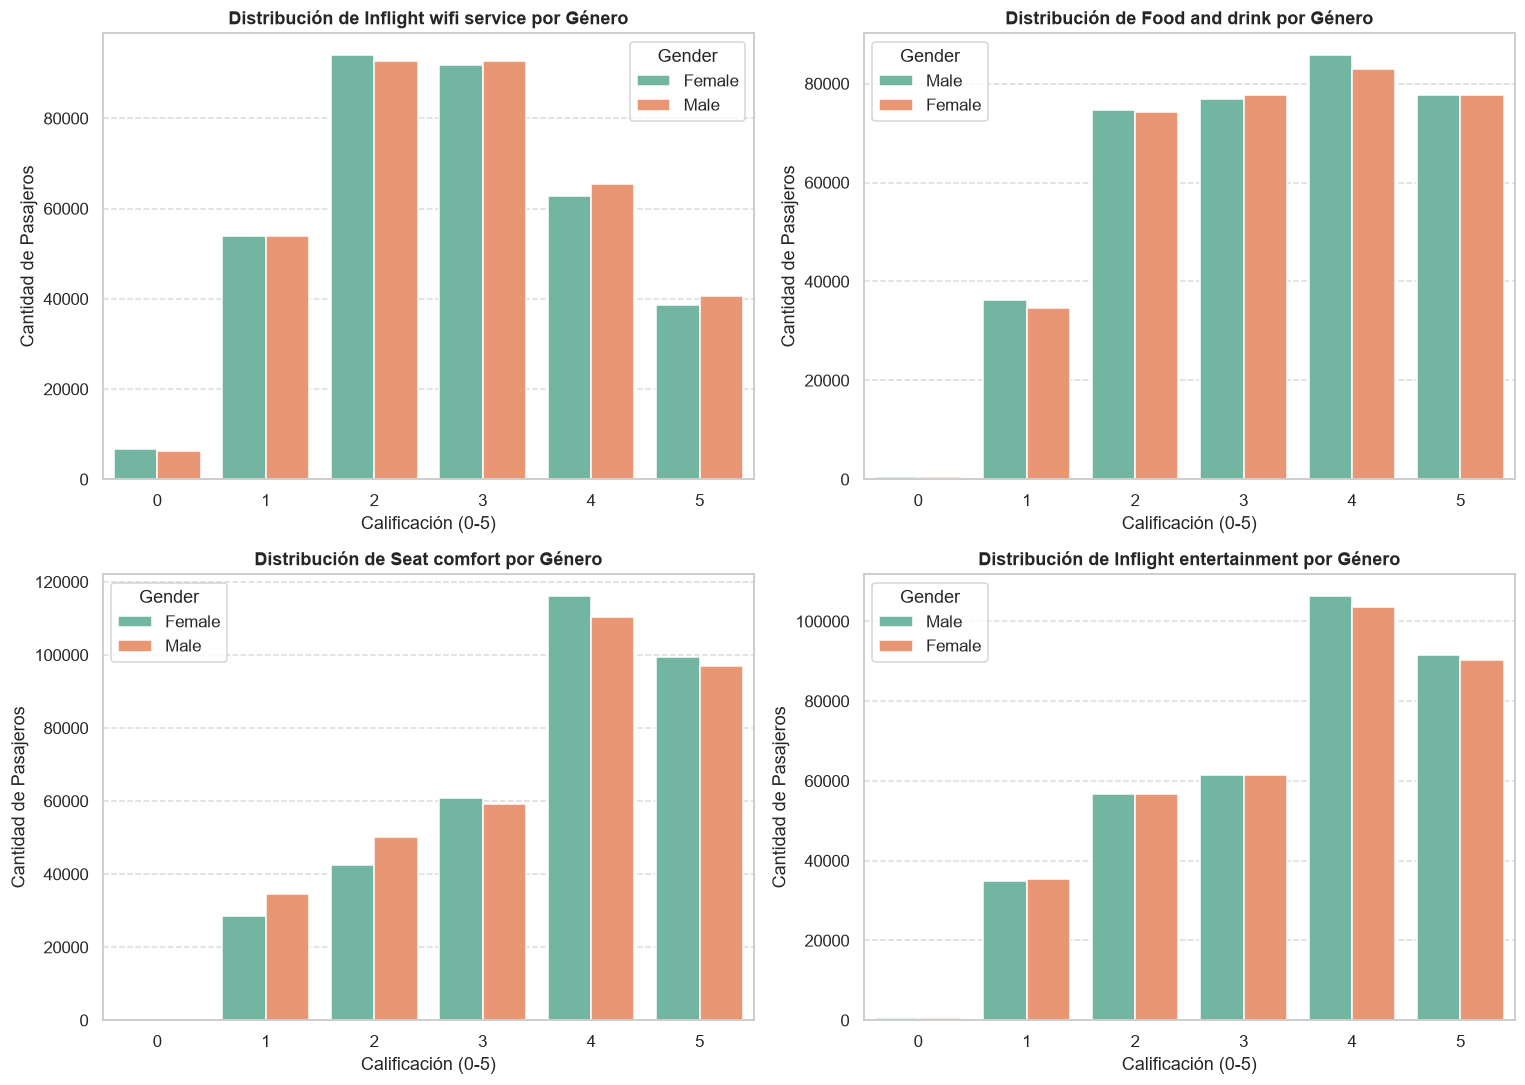

In [9]:
_cell_tag = 'seccion_17'
import matplotlib.pyplot as plt
import seaborn as sns

sample_cols = [
    'Inflight wifi service',
    'Food and drink', 
    'Seat comfort', 
    'Inflight entertainment'
]

# 2. Configuración de la figura (2 filas x 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# 3. Generación de gráficos de barras agrupados por género
for i, col in enumerate(sample_cols):
    sns.countplot(
        data=train, 
        x=col, 
        hue='Gender', 
        ax=axes[i], 
        palette='Set2'
    )
    axes[i].set_title(f'Distribución de {col} por Género', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Calificación (0-5)')
    axes[i].set_ylabel('Cantidad de Pasajeros')
    axes[i].legend(title='Gender')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

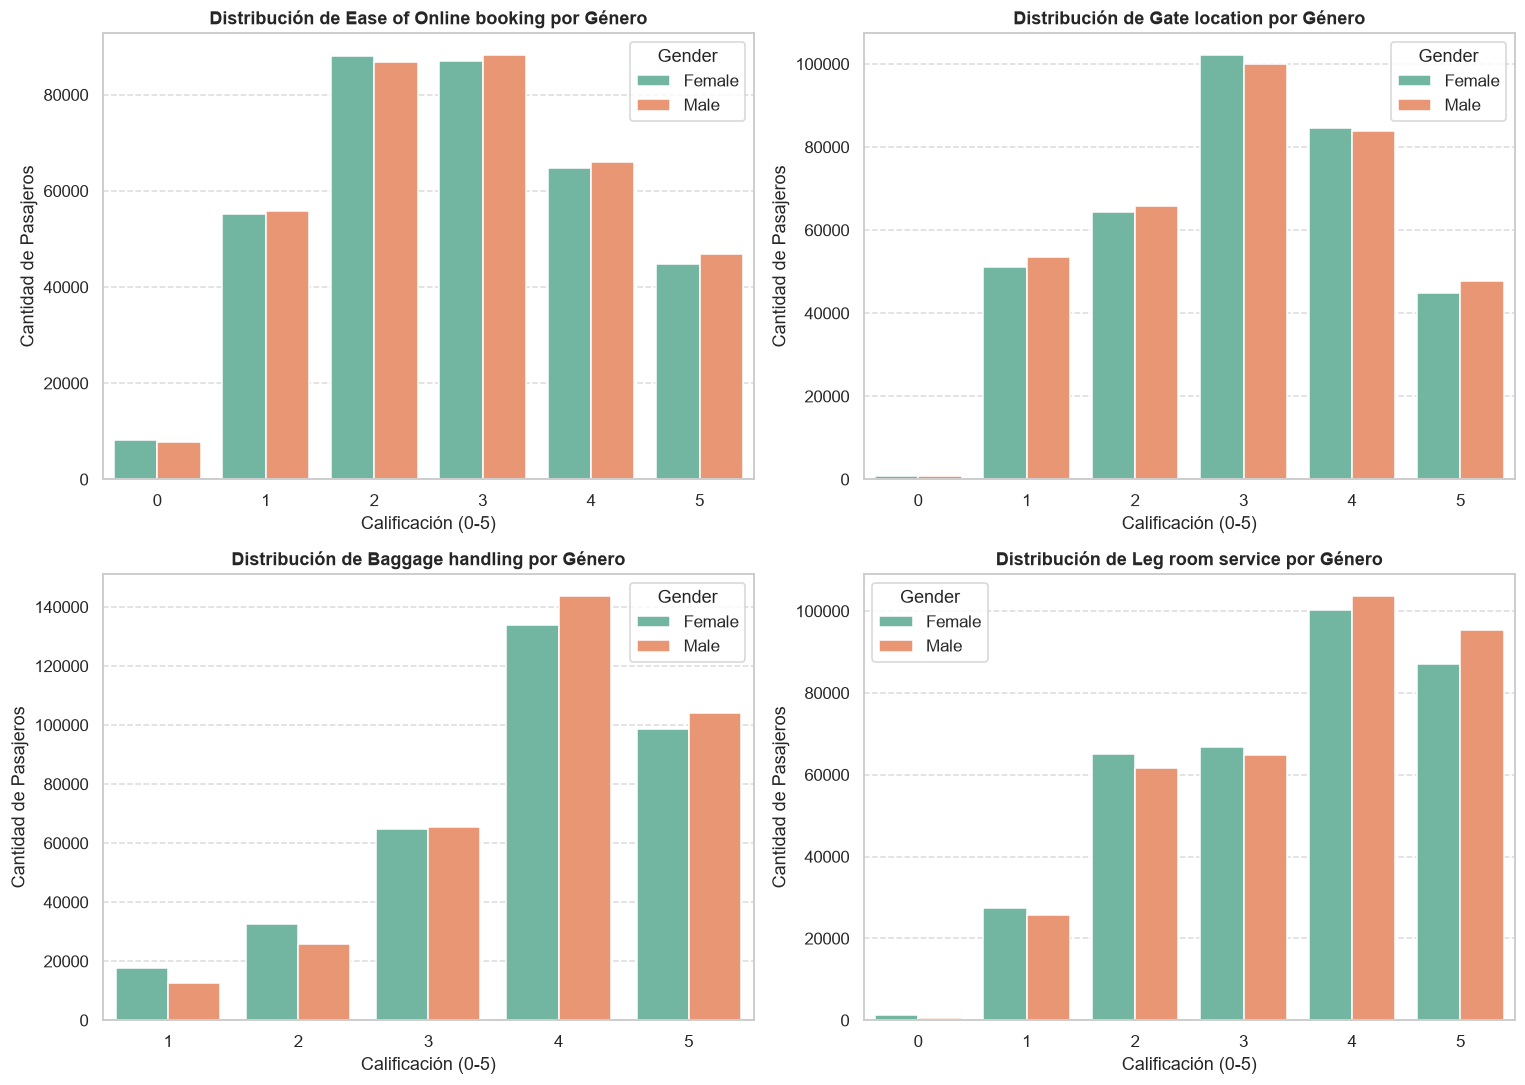

In [10]:
_cell_tag = 'seccion_18'
import matplotlib.pyplot as plt
import seaborn as sns

sample_cols_2 = [
    'Ease of Online booking', 
    'Gate location', 
    'Baggage handling', 
    'Leg room service'
]

# Configuración de la grilla (2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(sample_cols_2):
    sns.countplot(
        data=train, 
        x=col, 
        hue='Gender', 
        ax=axes[i], 
        palette='Set2'
    )
    axes[i].set_title(f'Distribución de {col} por Género', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Calificación (0-5)')
    axes[i].set_ylabel('Cantidad de Pasajeros')
    axes[i].legend(title='Gender')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 5. Promedio de calificaciones
Se conserva el nombre `mean_satisfaction`, pero se interpreta como **promedio de calificaciones de servicios**, distinto del objetivo final. Supone pesos iguales y distancias iguales entre categorías. Según la escala confirmada para este trabajo, 0 es la peor evaluación y 5 la mejor. El cero es válido. El promedio es exploratorio y supone distancias iguales entre niveles.

C:\Users\agust\AppData\Local\Temp\ipykernel_10188\2268778585.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='satisfaction', y='mean_satisfaction', palette='Set2')


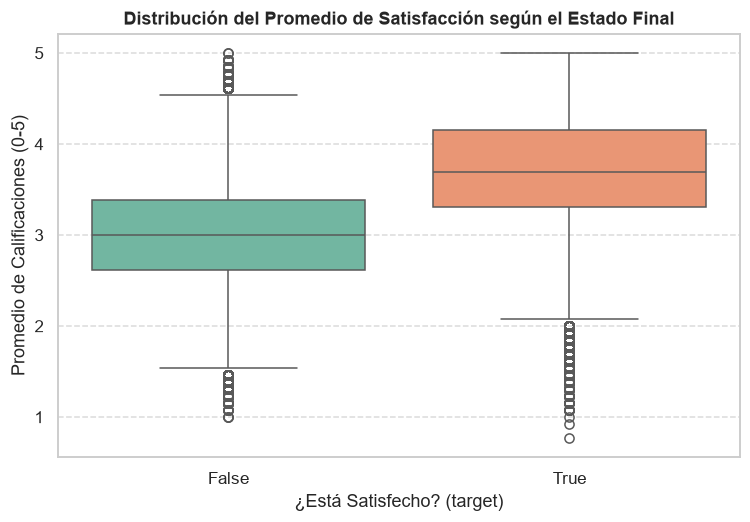

In [11]:
_cell_tag = 'seccion_20'
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear la nueva variable de promedio general
train['mean_satisfaction'] = train[ordinal_cols].mean(axis=1)

# 2. Visualizar la diferencia de promedios entre satisfechos y no satisfechos
plt.figure(figsize=(8, 5))
sns.boxplot(data=train, x='satisfaction', y='mean_satisfaction', palette='Set2')
plt.title('Distribución del Promedio de Satisfacción según el Estado Final', fontsize=12, fontweight='bold')
plt.xlabel('¿Está Satisfecho? (target)')
plt.ylabel('Promedio de Calificaciones (0-5)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 6. Distribución del objetivo
`True` corresponde a satisfecho; `False` a la clase no satisfecha según la codificación disponible. Confirmar la definición exacta de esta última clase en la fuente.

,Cantidad,Porcentaje
No satisfecho,389296,55.64
Satisfecho,310339,44.36


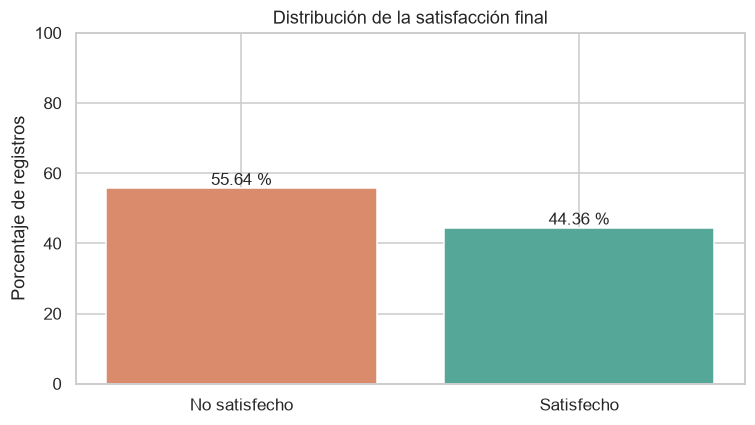

Accuracy al predecir siempre la clase mayoritaria: 55.64%


In [12]:
_cell_tag = 'seccion_23'
balance = train['satisfaction'].value_counts().reindex([False, True])
tabla_balance = pd.DataFrame({'Cantidad': balance, 'Porcentaje': balance / len(train) * 100})
tabla_balance.index = ['No satisfecho', 'Satisfecho']
display(tabla_balance.round(2))
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(tabla_balance.index, tabla_balance['Porcentaje'], color=['#D98B6C','#55A898'])
ax.set(ylabel='Porcentaje de registros', title='Distribución de la satisfacción final', ylim=(0,100))
for i, valor in enumerate(tabla_balance['Porcentaje']):
    ax.text(i, valor+1, f'{valor:.2f} %', ha='center')
plt.tight_layout(); plt.show()
print(f"Accuracy al predecir siempre la clase mayoritaria: {balance.max()/len(train):.2%}")


**Interpretación:** el 44,36 % está satisfecho y el 55,64 % no. No se observa un desbalance fuerte. La clase mayoritaria daría 55,64 % de accuracy. Si se utiliza ROC AUC, una puntuación constante da 0,5; son referencias diferentes. La comparación de modelos utiliza ROC AUC.

## 7. Satisfacción según características del viaje
Se comparan porcentajes dentro de cada grupo, acompañados por su tamaño.

,Cantidad,% Satisfechos
Gender,,
Female,347952,43.80
Male,351683,44.91


,Cantidad,% Satisfechos
Customer Type,,
Loyal Customer,576990,49.51
disloyal Customer,122645,20.09


,Cantidad,% Satisfechos
Type of Travel,,
Business travel,497441,58.43
Personal Travel,202194,9.73


,Cantidad,% Satisfechos
Class,,
Business,342212,72.53
Eco,327404,16.76
Eco Plus,30019,24.22


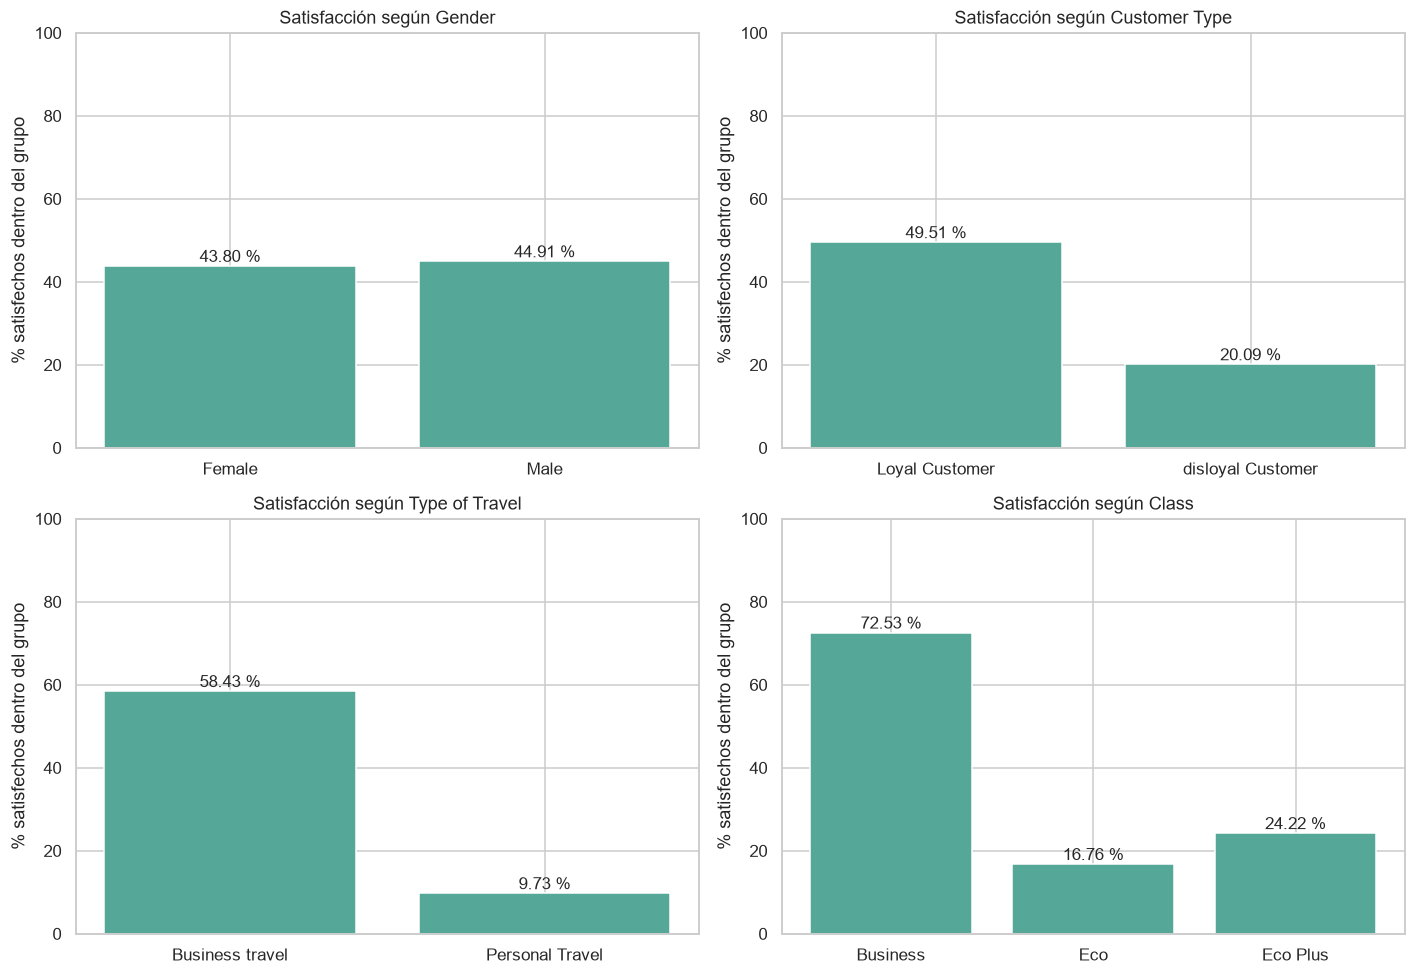

In [13]:
_cell_tag = 'seccion_26'
tablas_grupos = {}
fig, axes = plt.subplots(2,2,figsize=(13,9))
for ax, col in zip(axes.flat, cat_cols):
    tabla = train.groupby(col, observed=True)['satisfaction'].agg(['count','mean'])
    tabla.columns = ['Cantidad','Proporción satisfechos']
    tabla['% Satisfechos'] = tabla['Proporción satisfechos']*100
    tablas_grupos[col] = tabla
    display(tabla[['Cantidad','% Satisfechos']].round(2))
    ax.bar(tabla.index.astype(str),tabla['% Satisfechos'],color='#55A898')
    ax.set(title=f'Satisfacción según {col}',ylabel='% satisfechos dentro del grupo',ylim=(0,100))
    for j, v in enumerate(tabla['% Satisfechos']):
        ax.text(j,v+1,f'{v:.2f} %',ha='center')
plt.tight_layout(); plt.show()


**Interpretación:** Business presenta 72,53 % de satisfechos, frente a 16,76 % en Eco. Los viajes de negocios presentan 58,43 %, frente a 9,73 % en los personales. La diferencia entre géneros es mucho menor: aproximadamente 1,11 puntos porcentuales. Estas comparaciones son descriptivas y no controlan diferencias entre grupos ni prueban causalidad.

## 8. Calificaciones de servicios y significado del cero

,Cantidad de ceros,% de ceros
Inflight wifi service,13102,1.87
Departure/Arrival time convenient,25751,3.68
Ease of Online booking,16073,2.30
Gate location,1455,0.21
Food and drink,1014,0.14
Online boarding,9147,1.31
Seat comfort,838,0.12
Inflight entertainment,1020,0.15
On-board service,801,0.11
Leg room service,1693,0.24


,Cantidad,Proporción satisfechos
Inflight wifi service,,
0,13102,0.8873
1,107739,0.3907
2,186870,0.2704
3,184436,0.2762
4,128136,0.6222
5,79352,0.9504


,Cantidad,Proporción satisfechos
Online boarding,,
0,9147,0.6204
1,57588,0.1053
2,119297,0.0854
3,149783,0.1284
4,210950,0.6419
5,152870,0.8751


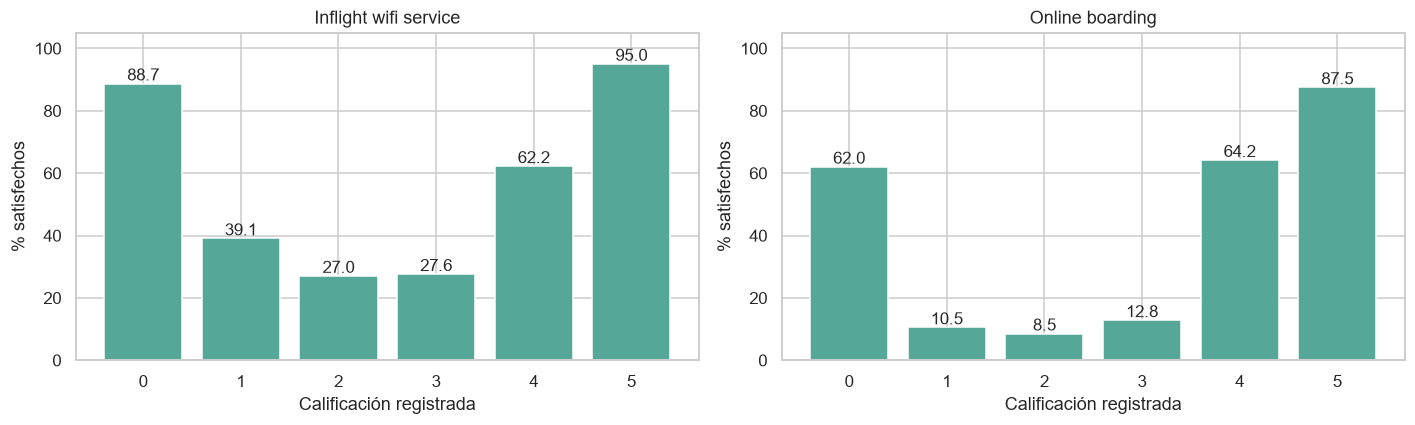

In [14]:
_cell_tag = 'seccion_29'
tabla_ceros = pd.DataFrame({
    'Cantidad de ceros': train[ordinal_cols].eq(0).sum(),
    '% de ceros': train[ordinal_cols].eq(0).mean()*100
})
display(tabla_ceros.round(2))
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax, col in zip(axes,['Inflight wifi service','Online boarding']):
    tabla = train.groupby(col)['satisfaction'].agg(['count','mean']).reindex(range(6))
    display(tabla.rename(columns={'count':'Cantidad','mean':'Proporción satisfechos'}).round(4))
    ax.bar(tabla.index,tabla['mean']*100,color='#55A898')
    ax.set(title=col,xlabel='Calificación registrada',ylabel='% satisfechos',ylim=(0,105),xticks=range(6))
    for calif, v in (tabla['mean']*100).items():
        ax.text(calif,v+1,f'{v:.1f}',ha='center')
plt.tight_layout(); plt.show()


**Interpretación:** el wifi con valor 0 presenta 88,73 % de satisfechos; con 1, 39,07 %; y con 5, 95,04 %. El patrón no es monótono. Según la escala confirmada para este trabajo, 0 es la peor evaluación y 5 la mejor. Se conservan todos estos valores. El patrón no monótono debe investigarse por segmentos; no demuestra causalidad.

## 9. Resumen del promedio de calificaciones y retrasos

In [15]:
_cell_tag = 'seccion_32'
display(train.groupby('satisfaction')['mean_satisfaction'].agg(['count','mean','median','std']).round(3))
# Categorías descriptivas; los nulos originales se mantienen identificados.
grupo_retraso = pd.cut(train_antes_limpieza['Arrival Delay in Minutes'],
    bins=[-1,0,15,60,float('inf')],labels=['Sin retraso','1–15 min','16–60 min','Más de 60 min'])
tabla_retraso = train_antes_limpieza.groupby(grupo_retraso,observed=True)['satisfaction'].agg(['count','mean'])
tabla_retraso['% Satisfechos'] = tabla_retraso['mean']*100
display(tabla_retraso[['count','% Satisfechos']].round(2))
print('Registros excluidos de esta tabla por retraso de llegada faltante:', int(grupo_retraso.isna().sum()))


,count,mean,median,std
satisfaction,,,,
False,389296,2.998,3.000,0.587
True,310339,3.698,3.692,0.589


,count,% Satisfechos
Arrival Delay in Minutes,,
Sin retraso,640415,45.21
1–15 min,40284,37.22
16–60 min,18334,30.59
Más de 60 min,310,30.97


Registros excluidos de esta tabla por retraso de llegada faltante: 292


**Interpretación:** el promedio de servicios es aproximadamente 3,00 en no satisfechos y 3,70 en satisfechos. Hay solapamiento entre grupos, como muestra el boxplot original. La tabla de retrasos permite explorar asociaciones sin ocultar cuántos registros tiene cada intervalo; no basta para atribuir un efecto causal.

## 10. Conclusiones preliminares y próximos pasos
- Los datos presentan pocos faltantes y no se detectan duplicados completos al excluir `id`.
- La satisfacción tiene una distribución relativamente equilibrada.
- Clase, tipo de viaje y fidelidad muestran diferencias descriptivas relevantes.
- El cero se conserva como la peor evaluación. Los promedios suponen distancias iguales entre niveles.
- La imputación se apoya en la relación entre retrasos, pero sigue siendo aproximada.

**Plan de modelado original (implementado en las secciones siguientes):**
1. Completar fuente, diccionario de variables, significado de las clases y métrica de evaluación. Definir el momento de predicción: varias evaluaciones de servicios y el retraso de llegada requieren información posterior al viaje.
2. Reservar validación estratificada desde `train`, con semilla fija. El `test` proporcionado no tiene etiquetas y no permite calcular métricas locales. Como ya se exploró el train completo, documentar ese hecho y evitar ajustar decisiones repetidamente al conjunto reservado.
3. Excluir `id` de los predictores. Ajustar transformaciones que aprendan parámetros únicamente en entrenamiento mediante un pipeline.
4. Construir una referencia constante y una regresión logística; después comparar un modelo de árboles. Reportar la métrica principal y, si corresponde, matriz de confusión, precisión y recall con umbral explícito.
5. Si se usa el promedio como predictor, calcularlo de la misma manera para entrenamiento, validación y test. Conservar el cero como evaluación válida.
6. Interpretar asociaciones predictivas sin presentarlas como causas de satisfacción.


# Modelado, interpretación y aplicación

## 11. Cuatro modelos de clasificación

**Objetivo:** predecir la satisfacción después del viaje, utilizando características del pasajero, del vuelo y sus evaluaciones de servicios. No es un modelo de predicción antes de viajar.

Se comparan cuatro familias: regresión logística (referencia lineal), árbol de decisión (reglas no lineales), Random Forest (ensamble de árboles) y HistGradientBoosting (árboles que corrigen errores sucesivamente). Se añade DummyClassifier como referencia, sin contarlo entre los cuatro.

Se utiliza ROC AUC como criterio (Como indica la competición). También se reportan accuracy, precision, recall, F1 y average precision. La clase positiva es satisfecho (1), con umbral fijo de 0,5.

Se reserva 20 % de train con estratificación y semilla 42. La exploración previa utilizó todo train: esta validación no es completamente ajena al análisis exploratorio. No se realiza búsqueda de hiperparámetros ni ajuste del umbral sobre ella. Los resultados son preliminares; para la siguiente etapa conviene validación cruzada dentro del conjunto de entrenamiento y una evaluación final independiente.


In [16]:
_cell_tag = 'seccion_36'
# 11.1. Datos y partición reproducible, independiente de variables del EDA
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay)

# Deja los tres CSV junto al notebook; también se admite una subcarpeta upload.
DATA_DIR = Path('.') if Path('train.csv').exists() else Path('upload')
datos_modelo = pd.read_csv(DATA_DIR / 'train.csv')
datos_test = pd.read_csv(DATA_DIR / 'test.csv')
plantilla = pd.read_csv(DATA_DIR / 'sample_submission.csv')
assert datos_modelo['satisfaction'].notna().all()
y = datos_modelo['satisfaction'].astype(str).str.lower().map({'true':1, 'false':0})
assert y.notna().all(), 'Revisar codificación del objetivo'
y = y.astype(int)
X = datos_modelo.drop(columns=['id', 'satisfaction']).copy()
X_test = datos_test.drop(columns='id').copy()
assert set(X.columns) == set(X_test.columns)
X_test = X_test[X.columns]
# Imputación determinista original: no aprende parámetros de validación ni test.
for frame in (X, X_test):
    frame['Arrival Delay in Minutes'] = frame['Arrival Delay in Minutes'].fillna(frame['Departure Delay in Minutes'])
# Se omite el promedio para conservar las evaluaciones originales sin redundancia.
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print(f'Entrenamiento: {len(X_fit):,}; validación: {len(X_val):,}; test sin etiquetas: {len(X_test):,}')
print('Proporción satisfechos:', y_fit.mean(), y_val.mean())
print('Predictores:', X.shape[1], '| ID excluido')


Entrenamiento: 559,708; validación: 139,927; test sin etiquetas: 299,844
Proporción satisfechos: 0.44357236273199596 0.4435741493778899
Predictores: 21 | ID excluido


### 11.2. Preprocesamiento e hiperparámetros
Las categorías nominales usan one-hot encoding y se ignoran categorías nuevas. Las variables numéricas conservan sus valores, incluidas las calificaciones 0–5. Solo la regresión logística se estandariza. Las medianas, modas, categorías y escalas se aprenden exclusivamente en entrenamiento dentro del pipeline.

Se limita la profundidad y el tamaño mínimo de hojas para contener el sobreajuste. Gradient boosting utiliza su propia partición interna para parada temprana. Los cuatro modelos usan todos los registros de entrenamiento; los tiempos dependen del equipo. El tratamiento numérico de calificaciones supone orden; el cero se conserva como la peor evaluación, según la definición confirmada para este trabajo.


In [17]:
_cell_tag = 'seccion_38'
# 11.2. Pipelines y modelos: sin dependencias de XGBoost/LightGBM/CatBoost
cat_modelo = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
num_modelo = X.columns.difference(cat_modelo).tolist()
def preparar(escalar=False):
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_num.append(('escalar', StandardScaler()))
    return ColumnTransformer([
        ('numericas', Pipeline(pasos_num), num_modelo),
        ('categoricas', Pipeline([
            ('imputar', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_modelo)
    ], sparse_threshold=0)

modelos = {
    'Regresión logística': Pipeline([('preparar', preparar(True)),
        ('modelo', LogisticRegression(max_iter=1000, random_state=42))]),
    'Árbol de decisión': Pipeline([('preparar', preparar()),
        ('modelo', DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, random_state=42))]),
    'Random Forest': Pipeline([('preparar', preparar()),
        ('modelo', RandomForestClassifier(n_estimators=150, max_depth=20,
            min_samples_leaf=5, max_features='sqrt', n_jobs=4, random_state=42))]),
    'Gradient boosting': Pipeline([('preparar', preparar()),
        ('modelo', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
            max_leaf_nodes=31, l2_regularization=1.0, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=15, random_state=42))])
}
print('Modelos listos:', list(modelos))


Modelos listos: ['Regresión logística', 'Árbol de decisión', 'Random Forest', 'Gradient boosting']


C:\Users\agust\AppData\Local\Temp\ipykernel_10188\325021602.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_modelo = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


In [18]:
_cell_tag = 'seccion_39'
# 12. Entrenar y comparar sobre exactamente la misma validación
referencia = DummyClassifier(strategy='prior').fit(X_fit, y_fit)
filas = []
prob_validacion = {}
for nombre, pipe in [('Referencia constante', referencia), *modelos.items()]:
    inicio = time.perf_counter()
    if nombre != 'Referencia constante':
        pipe.fit(X_fit, y_fit)
    segundos = time.perf_counter() - inicio
    proba = pipe.predict_proba(X_val)[:, list(pipe.classes_).index(1)]
    pred = (proba >= 0.5).astype(int)
    prob_validacion[nombre] = proba
    filas.append({'Modelo': nombre, 'ROC AUC': roc_auc_score(y_val, proba),
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred), 'F1': f1_score(y_val, pred),
        'Average precision': average_precision_score(y_val, proba),
        'Segundos de ajuste': segundos})
    print(f'{nombre}: ROC AUC={filas[-1]["ROC AUC"]:.5f}; ajuste={segundos:.1f} s', flush=True)
comparacion = pd.DataFrame(filas).sort_values('ROC AUC', ascending=False).reset_index(drop=True)
display(comparacion.round(5))


Referencia constante: ROC AUC=0.50000; ajuste=0.0 s
Regresión logística: ROC AUC=0.92045; ajuste=4.1 s
Árbol de decisión: ROC AUC=0.95255; ajuste=12.6 s
Random Forest: ROC AUC=0.95625; ajuste=97.6 s
Gradient boosting: ROC AUC=0.95701; ajuste=17.3 s


,Modelo,ROC AUC,Accuracy,Precision,Recall,F1,Average precision,Segundos de ajuste
0,Gradient boosting,0.95701,0.92385,0.92520,0.90117,0.91303,0.94090,17.33770
1,Random Forest,0.95625,0.92420,0.92706,0.89992,0.91328,0.93980,97.63838
2,Árbol de decisión,0.95255,0.91868,0.92434,0.88948,0.90657,0.93218,12.60432
3,Regresión logística,0.92045,0.87809,0.87484,0.84622,0.86029,0.90891,4.07837
4,Referencia constante,0.50000,0.55643,0.00000,0.00000,0.00000,0.44357,0.00000


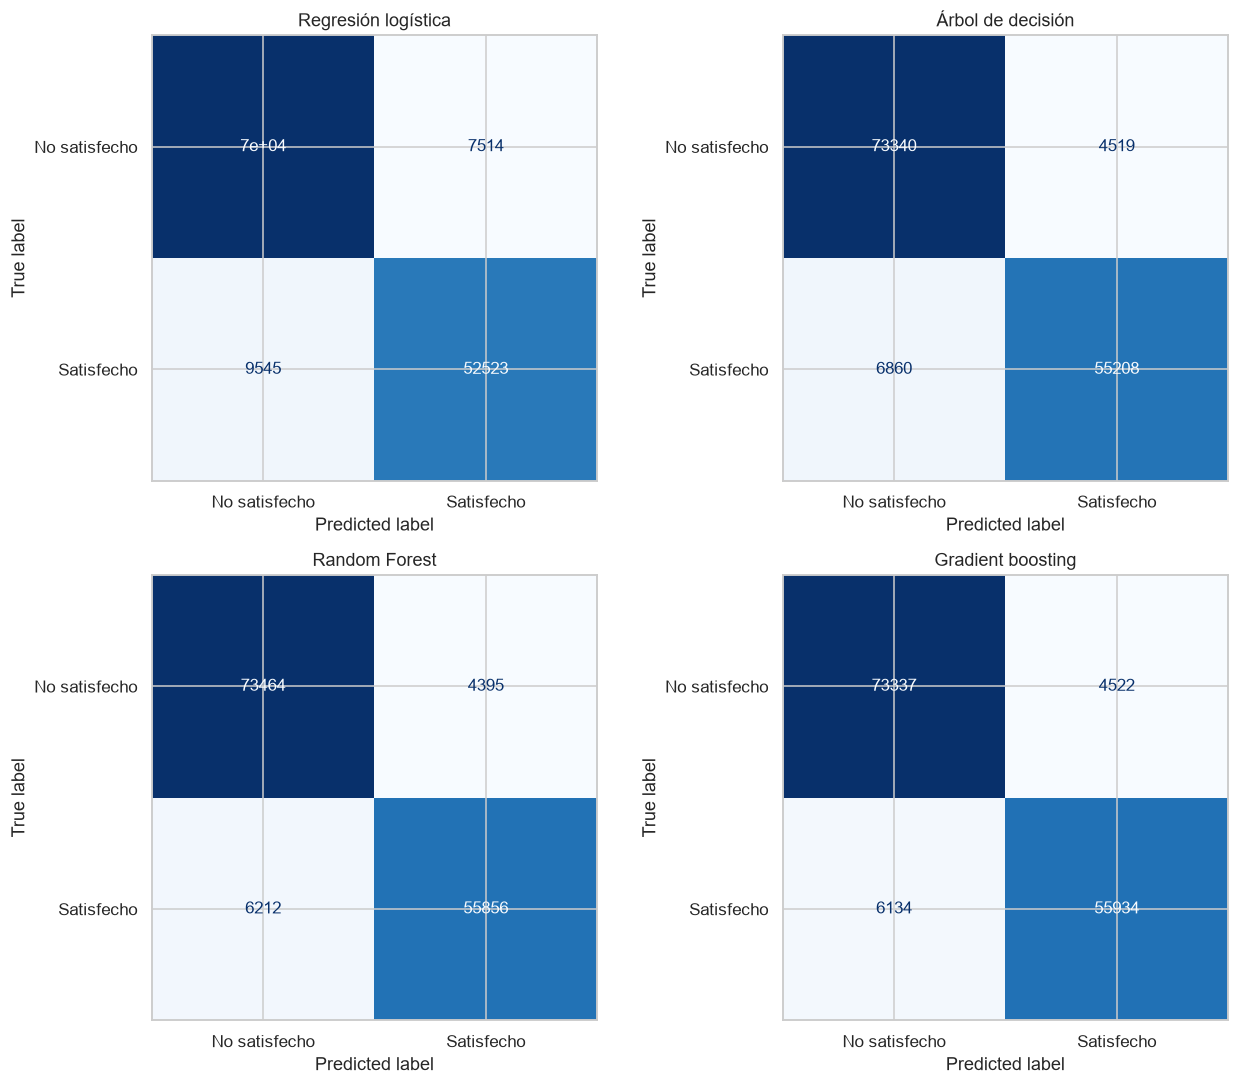

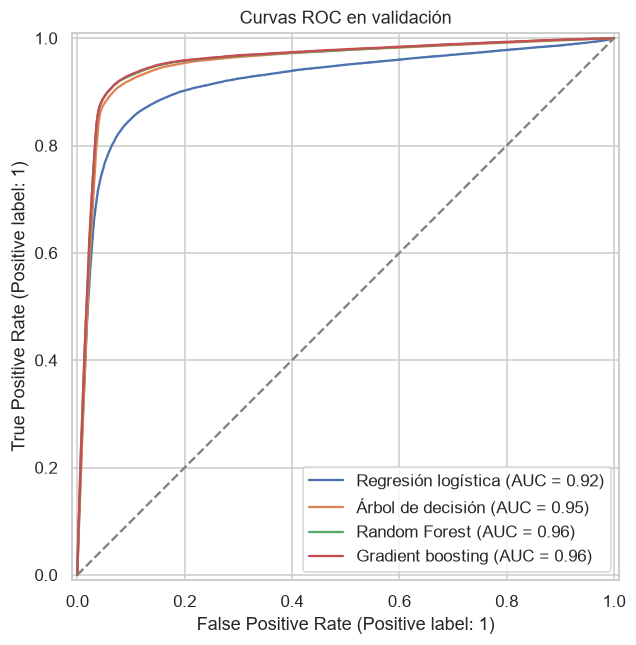

,Modelo,AUC entrenamiento,AUC validación,Brecha
0,Regresión logística,0.92187,0.92045,0.00142
1,Árbol de decisión,0.95821,0.95255,0.00566
2,Random Forest,0.97736,0.95625,0.02112
3,Gradient boosting,0.96134,0.95701,0.00432


Mejor modelo provisional por ROC AUC: Gradient boosting
               precision    recall  f1-score   support

No satisfecho     0.9228    0.9419    0.9323     77859
   Satisfecho     0.9252    0.9012    0.9130     62068

     accuracy                         0.9238    139927
    macro avg     0.9240    0.9215    0.9226    139927
 weighted avg     0.9239    0.9238    0.9237    139927



In [19]:
_cell_tag = 'seccion_40'
# 13. Diagnóstico visual y diferencia entre entrenamiento y validación
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (nombre, pipe) in zip(axes.flat, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, prob_validacion[nombre] >= 0.5,
        display_labels=['No satisfecho', 'Satisfecho'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nombre)
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 6))
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_val, prob_validacion[nombre], name=nombre, ax=ax)
ax.plot([0,1], [0,1], '--', color='gray')
ax.set_title('Curvas ROC en validación')
fig.tight_layout()
plt.show()
filas_brecha = []
for nombre, pipe in modelos.items():
    auc_fit = roc_auc_score(y_fit, pipe.predict_proba(X_fit)[:, 1])
    auc_val = roc_auc_score(y_val, prob_validacion[nombre])
    filas_brecha.append({'Modelo': nombre, 'AUC entrenamiento': auc_fit,
        'AUC validación': auc_val, 'Brecha': auc_fit - auc_val})
display(pd.DataFrame(filas_brecha).round(5))
mejor_nombre = comparacion.loc[comparacion.Modelo.isin(modelos)].iloc[0]['Modelo']
print('Mejor modelo provisional por ROC AUC:', mejor_nombre)
print(classification_report(y_val, prob_validacion[mejor_nombre] >= 0.5,
    target_names=['No satisfecho', 'Satisfecho'], digits=4))


### 14. Resultados de la ejecución

La siguiente tabla se genera con esta ejecución. ROC AUC es el criterio principal; accuracy y F1 usan umbral 0,5. La selección entre alternativas introduce optimismo. La validación fue explorada previamente durante el EDA: los resultados son preliminares y no equivalen al test de Kaggle.


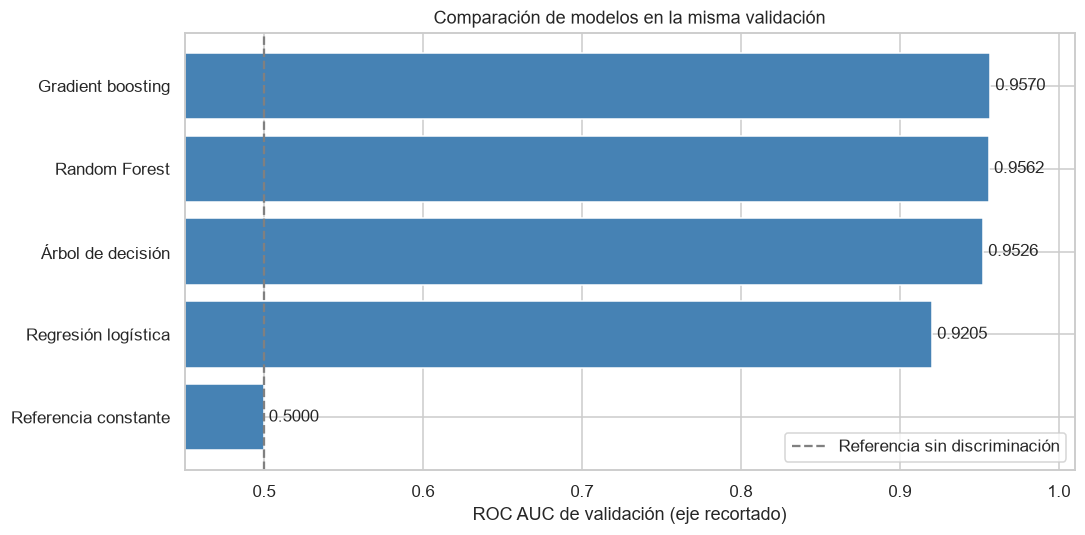

,Modelo,ROC AUC,Accuracy,Precision,Recall,F1,Average precision,Segundos de ajuste
0,Gradient boosting,0.95701,0.92385,0.92520,0.90117,0.91303,0.94090,17.33770
1,Random Forest,0.95625,0.92420,0.92706,0.89992,0.91328,0.93980,97.63838
2,Árbol de decisión,0.95255,0.91868,0.92434,0.88948,0.90657,0.93218,12.60432
3,Regresión logística,0.92045,0.87809,0.87484,0.84622,0.86029,0.90891,4.07837
4,Referencia constante,0.50000,0.55643,0.00000,0.00000,0.00000,0.44357,0.00000


In [20]:
_cell_tag = 'comparacion_modelos'
datos_grafico = comparacion.sort_values('ROC AUC')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(datos_grafico['Modelo'], datos_grafico['ROC AUC'], color='steelblue')
for j, valor in enumerate(datos_grafico['ROC AUC']):
    ax.text(valor + 0.003, j, f'{valor:.4f}', va='center')
ax.set(xlim=(0.45, 1.01), xlabel='ROC AUC de validación (eje recortado)',
       title='Comparación de modelos en la misma validación')
ax.axvline(0.5, linestyle='--', color='gray', label='Referencia sin discriminación')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()
display(comparacion.round(5))


In [21]:
_cell_tag = 'seccion_42'
# 15. Predicciones para test: reentrenamiento final, después de evaluar
from sklearn.base import clone
modelo_final = clone(modelos[mejor_nombre])
modelo_final.fit(X, y)
prob_test = modelo_final.predict_proba(X_test)[:, list(modelo_final.classes_).index(1)]
assert len(plantilla) == len(datos_test)
assert plantilla['id'].equals(datos_test['id']), 'El orden de los ID difiere de la plantilla'
assert np.isfinite(prob_test).all() and ((prob_test >= 0) & (prob_test <= 1)).all()
submission = plantilla.copy()
submission['satisfaction'] = prob_test
OUTPUT_DIR = Path('resultados_modelos')
OUTPUT_DIR.mkdir(exist_ok=True)
submission.to_csv(OUTPUT_DIR / 'submission_mejor_modelo.csv', index=False)
comparacion.to_csv(OUTPUT_DIR / 'comparacion_modelos.csv', index=False)
print('Modelo final:', mejor_nombre)
print('Predicciones guardadas:', submission.shape)
print('Se exportan probabilidades, como sugiere la plantilla. Confirmar formato oficial antes de enviar.')
display(submission.head())


Modelo final: Gradient boosting
Predicciones guardadas: (299844, 2)
Se exportan probabilidades, como sugiere la plantilla. Confirmar formato oficial antes de enviar.


,id,satisfaction
0,699635,0.163840
1,699636,0.909051
2,699637,0.903282
3,699638,0.077923
4,699639,0.045430


## 16. ¿Qué variables utiliza más el modelo para predecir?

El modelo obtuvo un buen resultado, pero también queremos entender en qué información se apoya. Para esto usamos **importancia por permutación**: mezclamos los valores de una variable entre pasajeros y observamos cuánto cae el ROC AUC. Si cae bastante, el modelo dependía de esa información para distinguir entre satisfechos y no satisfechos.

Usamos el pipeline del mejor modelo **entrenado solo con `X_fit`**, no `modelo_final`, porque este último ya fue ajustado con todo train, incluida la validación. Permutamos las columnas originales antes del preprocesamiento para obtener una importancia por variable, incluso cuando se transforma en varias columnas con one-hot encoding.

Para limitar el tiempo, tomamos hasta 15.000 registros de validación mediante muestreo estratificado con semilla fija y repetimos cada permutación cinco veces. Los resultados describen esta muestra y este modelo; no se usan para volver a elegir variables o ajustar hiperparámetros.

Modelo analizado: Gradient boosting
Muestra de validación: 15,000 registros
ROC AUC antes de permutar: 0.95748


,Variable,Caída media de ROC AUC,Desviación entre repeticiones
0,Type of Travel,0.06983,0.00108
1,Inflight wifi service,0.04447,0.00115
2,Customer Type,0.02726,0.00079
3,Online boarding,0.00995,0.00059
4,Class,0.00555,0.00044
5,Baggage handling,0.00482,0.00051
6,Checkin service,0.00401,0.00035
7,Seat comfort,0.00312,0.00035
8,On-board service,0.00241,0.00016
9,Cleanliness,0.00235,0.00025


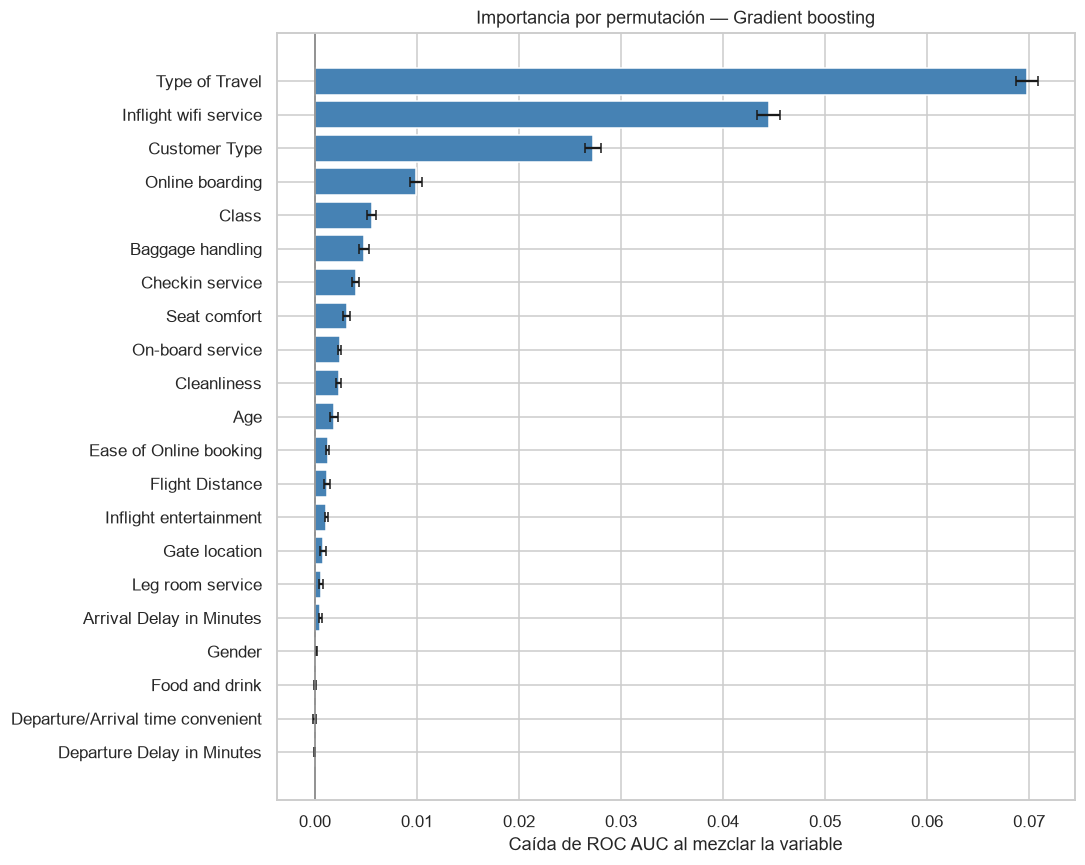

Variables con mayor caída media de ROC AUC:
- Type of Travel: 0.06983
- Inflight wifi service: 0.04447
- Customer Type: 0.02726
- Online boarding: 0.00995
- Class: 0.00555


In [22]:
_cell_tag = 'seccion_44'
from sklearn.inspection import permutation_importance

# Ejecutar primero las secciones 11–12 para tener los modelos entrenados.
modelo_interpretar = modelos[mejor_nombre]
n_interpretacion = min(15_000, len(X_val))
if len(X_val) > n_interpretacion:
    X_interpretar, _, y_interpretar, _ = train_test_split(
        X_val, y_val, train_size=n_interpretacion,
        stratify=y_val, random_state=42
    )
else:
    X_interpretar, y_interpretar = X_val.copy(), y_val.copy()

prob_interpretar = modelo_interpretar.predict_proba(X_interpretar)[
    :, list(modelo_interpretar.classes_).index(1)
]
auc_base = roc_auc_score(y_interpretar, prob_interpretar)
print(f'Modelo analizado: {mejor_nombre}')
print(f'Muestra de validación: {len(X_interpretar):,} registros')
print(f'ROC AUC antes de permutar: {auc_base:.5f}')

resultado_perm = permutation_importance(
    modelo_interpretar, X_interpretar, y_interpretar,
    scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=1
)
importancias_perm = pd.DataFrame({
    'Variable': X_interpretar.columns,
    'Caída media de ROC AUC': resultado_perm.importances_mean,
    'Desviación entre repeticiones': resultado_perm.importances_std
}).sort_values('Caída media de ROC AUC', ascending=False).reset_index(drop=True)
display(importancias_perm.round(5))

# Mostramos todas las variables, incluidas las importancias negativas.
grafico_perm = importancias_perm.sort_values('Caída media de ROC AUC')
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(
    grafico_perm['Variable'], grafico_perm['Caída media de ROC AUC'],
    xerr=grafico_perm['Desviación entre repeticiones'],
    color='steelblue', capsize=3
)
ax.axvline(0, color='gray', linewidth=1)
ax.set_xlabel('Caída de ROC AUC al mezclar la variable')
ax.set_title(f'Importancia por permutación — {mejor_nombre}')
fig.tight_layout()
plt.show()

print('Variables con mayor caída media de ROC AUC:')
for _, fila in importancias_perm.head(5).iterrows():
    print(f"- {fila['Variable']}: {fila['Caída media de ROC AUC']:.5f}")

### ¿Cómo leer el resultado?

- **Caída positiva y grande:** el modelo se apoya en esa variable para predecir en esta muestra.
- **Caída cercana a cero:** mezclarla apenas cambia el resultado. No demuestra que el servicio sea irrelevante para los pasajeros; otras variables pueden aportar información parecida.
- **Caída negativa:** al mezclarla, el resultado mejora. Puede reflejar variabilidad o información poco útil para este modelo; no significa que ese servicio perjudique a los pasajeros.
- Las barras de error muestran la desviación entre las cinco permutaciones. **No son intervalos de confianza** ni incluyen toda la incertidumbre del muestreo y entrenamiento.

La importancia no indica si una valoración alta aumenta o disminuye la predicción. Además, las variables relacionadas pueden repartirse la importancia, y mezclarlas puede generar combinaciones poco habituales.

### ¿Cómo se conecta con una idea de negocio?

Podríamos ofrecer un informe que ayude a una aerolínea a explorar la experiencia de sus pasajeros. Este gráfico sería una de sus herramientas: muestra qué información utiliza más el modelo y orienta qué aspectos convendría investigar con mayor detalle.

Por ejemplo, **si** la comodidad del asiento apareciera entre las primeras variables, propondríamos revisar sus evaluaciones por clase y tipo de viaje y contrastarlas con comentarios de pasajeros. No concluiríamos directamente que cambiar los asientos aumentará la satisfacción.

La propuesta sería comenzar con un diagnóstico y, si resulta útil, ofrecer actualizaciones periódicas del análisis. Antes de cobrar por el servicio, habría que probarlo con datos de una aerolínea y comprobar si ayuda a tomar decisiones concretas.

**Límite del análisis:** estas variables se conocen después del viaje. La importancia explica el comportamiento predictivo del modelo, no las causas de satisfacción ni el beneficio económico de una intervención. El orden obtenido con estos datos de Kaggle debe validarse antes de trasladarlo a una aerolínea real.

## 17. Oportunidades de mejora por clase de viaje

Comparamos **Eco, Eco Plus y Business** sin PCA. Business es la categoría disponible; no equivale necesariamente a primera clase. Buscamos servicios que combinen evaluaciones bajas y alta importancia predictiva, sin asumir de antemano las preferencias de cada grupo.

La escala confirmada para el trabajo va de **0 (peor) a 5 (mejor)**: el cero no es un faltante. Definimos notas bajas como **0–2**, un criterio descriptivo explícito. Los promedios suponen distancias iguales entre niveles.

**Ejecutar primero las secciones 11–12.** Usamos la partición de validación y el modelo global ajustado solo con X_fit. No usamos modelo_final, que ya vio toda la muestra. Este es un diagnóstico exploratorio posterior a seleccionar el modelo, no una evaluación independiente.


,Registros,Satisfacción (%)
Class,,
Eco,65438,16.74
Eco Plus,6044,24.21
Business,68445,72.54


,Clase,Servicio,Registros del segmento,Evaluaciones válidas,Promedio (0–5),Evaluaciones bajas (%)
0,Eco,Inflight wifi service,65438,65438,2.65,46.84
1,Eco,Departure/Arrival time convenient,65438,65438,3.33,29.16
2,Eco,Ease of Online booking,65438,65438,2.61,47.79
3,Eco,Gate location,65438,65438,2.98,30.22
4,Eco,Food and drink,65438,65438,3.10,36.16
5,Eco,Online boarding,65438,65438,2.80,41.44
6,Eco,Seat comfort,65438,65438,3.16,33.45
7,Eco,Inflight entertainment,65438,65438,3.08,36.71
8,Eco,On-board service,65438,65438,3.19,29.31
9,Eco,Leg room service,65438,65438,3.12,35.50


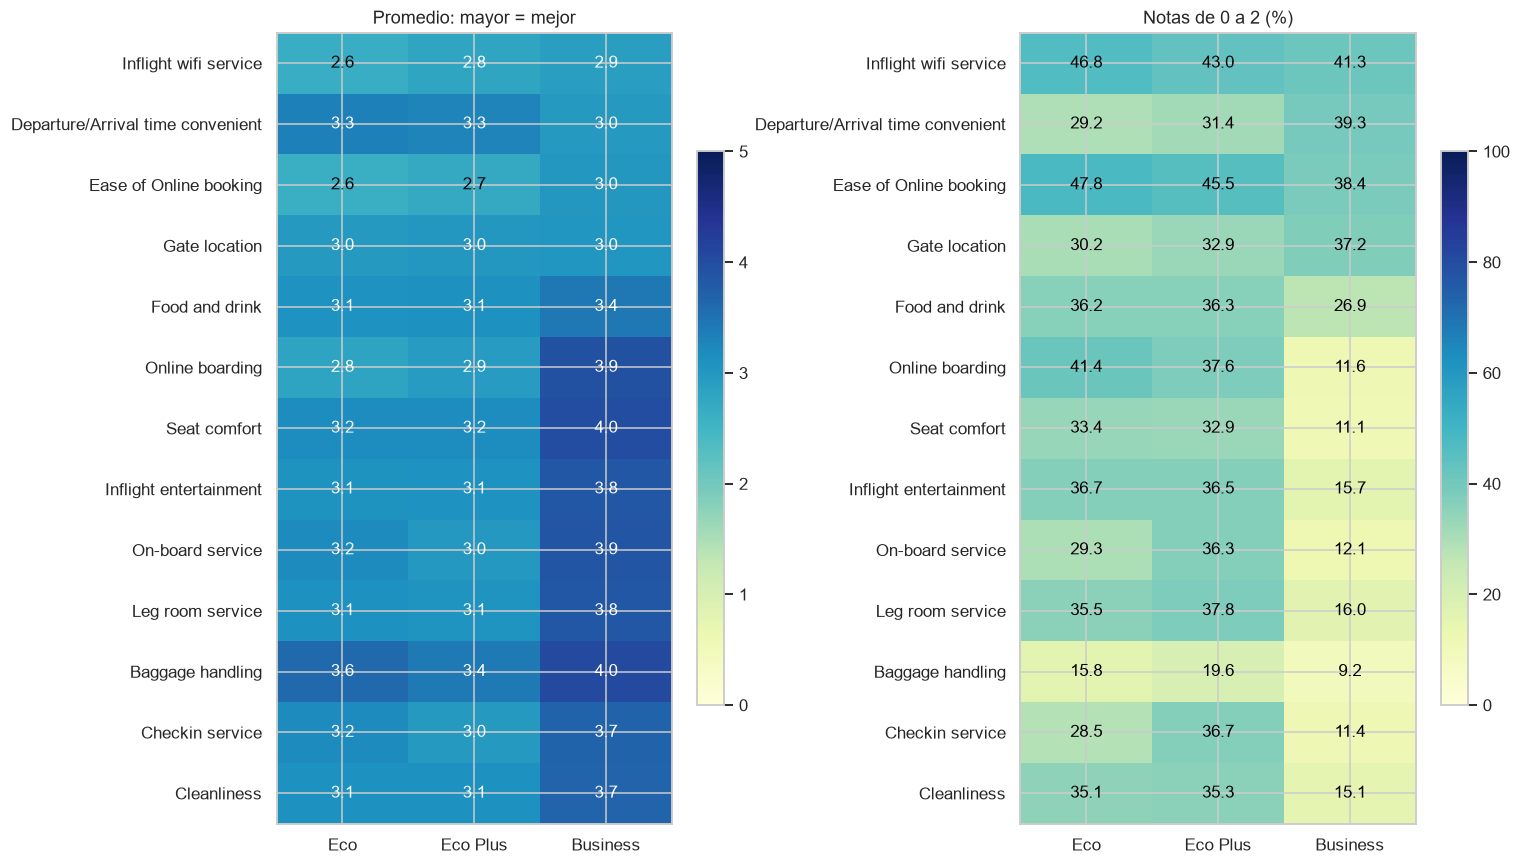

In [23]:
_cell_tag = 'seccion_47'
# 17.1. Evaluación de los 13 servicios por clase: toda la validación
servicios_clase = [
    'Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness'
]
clases_analisis = ['Eco', 'Eco Plus', 'Business']
assert set(servicios_clase + ['Class']).issubset(X_val.columns)
assert X_val['Class'].isin(clases_analisis).all()
val_clase = X_val.copy()
val_clase['_satisfecho'] = y_val.reindex(val_clase.index)
assert val_clase['_satisfecho'].notna().all()
filas_servicios = []
for clase in clases_analisis:
    grupo = val_clase.loc[val_clase['Class'].eq(clase)]
    for servicio in servicios_clase:
        valores = grupo[servicio].dropna()
        assert valores.between(0, 5).all(), f'Fuera de escala: {servicio}'
        filas_servicios.append({
            'Clase': clase, 'Servicio': servicio,
            'Registros del segmento': len(grupo),
            'Evaluaciones válidas': len(valores),
            'Promedio (0–5)': valores.mean(),
            'Evaluaciones bajas (%)': 100 * valores.le(2).mean()
        })
evaluaciones_clase = pd.DataFrame(filas_servicios)
resumen_clases = val_clase.groupby('Class')['_satisfecho'].agg(
    Registros='size', Satisfaccion='mean'
).reindex(clases_analisis)
resumen_clases['Satisfacción (%)'] = resumen_clases.pop('Satisfaccion') * 100
display(resumen_clases.round(2))
display(evaluaciones_clase.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, metrica, limite, titulo in [
    (axes[0], 'Promedio (0–5)', 5, 'Promedio: mayor = mejor'),
    (axes[1], 'Evaluaciones bajas (%)', 100, 'Notas de 0 a 2 (%)')
]:
    tabla = evaluaciones_clase.pivot(index='Servicio', columns='Clase', values=metrica)
    tabla = tabla.reindex(index=servicios_clase, columns=clases_analisis)
    im = ax.imshow(tabla.to_numpy(), aspect='auto', cmap='YlGnBu', vmin=0, vmax=limite)
    ax.set_xticks(range(len(clases_analisis)), clases_analisis)
    ax.set_yticks(range(len(servicios_clase)), servicios_clase)
    for i in range(len(servicios_clase)):
        for j in range(len(clases_analisis)):
            valor = tabla.iloc[i, j]
            ax.text(j, i, f'{valor:.1f}', ha='center', va='center',
                    color='white' if valor > limite * 0.55 else 'black')
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
plt.show()


### 17.2. Importancia predictiva dentro de cada clase

Permutamos cada servicio **entre pasajeros de la misma clase**, manteniendo las demás variables. Medimos cuánto cae el ROC AUC del mismo modelo global en cada segmento. Usamos hasta **5.000 registros por clase**, estratificados por satisfacción, cinco permutaciones y semilla fija para limitar el tiempo. No permutamos Class porque es constante dentro del grupo.

Una caída grande indica dependencia predictiva del modelo. No indica cuánto subiría la satisfacción al mejorar ese servicio. Las variables relacionadas pueden compartir importancia. Los grupos con datos insuficientes de ambas respuestas se omiten y se informa.


In [24]:
_cell_tag = 'seccion_49'
# Permutación manual: solo servicios, conservando todas las entradas del pipeline.
modelo_por_clase = modelos[mejor_nombre]  # No usar modelo_final
filas_importancia, filas_diagnostico = [], []
for clase in clases_analisis:
    X_grupo = X_val.loc[X_val['Class'].eq(clase)].copy()
    y_grupo = y_val.reindex(X_grupo.index)
    conteos = y_grupo.value_counts()
    if len(conteos) < 2 or conteos.min() < 2:
        print(f'{clase}: datos insuficientes de ambas respuestas; se omite.')
        continue
    if len(X_grupo) > 5_000:
        X_grupo, _, y_grupo, _ = train_test_split(
            X_grupo, y_grupo, train_size=5_000, stratify=y_grupo, random_state=42
        )
    pos = list(modelo_por_clase.classes_).index(1)
    auc_base_clase = roc_auc_score(
        y_grupo, modelo_por_clase.predict_proba(X_grupo)[:, pos]
    )
    filas_diagnostico.append({
        'Clase': clase, 'Muestra para importancia': len(X_grupo),
        'ROC AUC antes de permutar': auc_base_clase
    })
    rng_perm = np.random.RandomState(42)
    for servicio in servicios_clase:
        caidas = []
        X_permutado = X_grupo.copy()
        for repeticion in range(5):
            X_permutado[servicio] = rng_perm.permutation(X_grupo[servicio].to_numpy())
            p_perm = modelo_por_clase.predict_proba(X_permutado)[:, pos]
            caidas.append(auc_base_clase - roc_auc_score(y_grupo, p_perm))
        filas_importancia.append({
            'Clase': clase, 'Servicio': servicio,
            'Caída media ROC AUC': np.mean(caidas),
            'Desviación permutaciones': np.std(caidas)
        })
importancia_clase = pd.DataFrame(filas_importancia)
if importancia_clase.empty:
    raise ValueError('No hay segmentos con datos suficientes para ROC AUC.')
diagnostico_clase = pd.DataFrame(filas_diagnostico)
prioridades_clase = evaluaciones_clase.merge(
    importancia_clase, on=['Clase', 'Servicio'], how='inner', validate='one_to_one'
)
print(f'Modelo global analizado: {mejor_nombre}')
display(diagnostico_clase.round(5))
for clase in clases_analisis:
    print(clase)
    display(prioridades_clase.loc[prioridades_clase['Clase'].eq(clase)]
            .sort_values('Caída media ROC AUC', ascending=False).round(4))


Modelo global analizado: Gradient boosting


,Clase,Muestra para importancia,ROC AUC antes de permutar
0,Eco,5000,0.90377
1,Eco Plus,5000,0.91764
2,Business,5000,0.92949


Eco


,Clase,Servicio,Registros del segmento,Evaluaciones válidas,Promedio (0–5),Evaluaciones bajas (%),Caída media ROC AUC,Desviación permutaciones
0,Eco,Inflight wifi service,65438,65438,2.6451,46.8413,0.1038,0.0022
5,Eco,Online boarding,65438,65438,2.8020,41.4423,0.0085,0.0018
10,Eco,Baggage handling,65438,65438,3.6002,15.8073,0.0072,0.0012
11,Eco,Checkin service,65438,65438,3.1853,28.4850,0.0071,0.0009
8,Eco,On-board service,65438,65438,3.1866,29.3071,0.0054,0.0010
12,Eco,Cleanliness,65438,65438,3.1112,35.0698,0.0026,0.0006
2,Eco,Ease of Online booking,65438,65438,2.6116,47.7857,0.0026,0.0012
6,Eco,Seat comfort,65438,65438,3.1646,33.4485,0.0020,0.0005
1,Eco,Departure/Arrival time convenient,65438,65438,3.3303,29.1635,0.0015,0.0005
7,Eco,Inflight entertainment,65438,65438,3.0848,36.7080,0.0012,0.0010


Eco Plus


,Clase,Servicio,Registros del segmento,Evaluaciones válidas,Promedio (0–5),Evaluaciones bajas (%),Caída media ROC AUC,Desviación permutaciones
13,Eco Plus,Inflight wifi service,6044,6044,2.7755,43.0179,0.0878,0.0017
18,Eco Plus,Online boarding,6044,6044,2.9312,37.5910,0.0146,0.0016
23,Eco Plus,Baggage handling,6044,6044,3.4067,19.6228,0.0109,0.0006
25,Eco Plus,Cleanliness,6044,6044,3.1104,35.2747,0.0063,0.0006
24,Eco Plus,Checkin service,6044,6044,2.9692,36.6810,0.0051,0.0006
21,Eco Plus,On-board service,6044,6044,2.9897,36.3336,0.0050,0.0016
19,Eco Plus,Seat comfort,6044,6044,3.1711,32.8756,0.0041,0.0009
15,Eco Plus,Ease of Online booking,6044,6044,2.7032,45.5162,0.0029,0.0003
20,Eco Plus,Inflight entertainment,6044,6044,3.0890,36.4825,0.0008,0.0004
22,Eco Plus,Leg room service,6044,6044,3.0624,37.7565,0.0005,0.0003


Business


,Clase,Servicio,Registros del segmento,Evaluaciones válidas,Promedio (0–5),Evaluaciones bajas (%),Caída media ROC AUC,Desviación permutaciones
26,Business,Inflight wifi service,68445,68445,2.9061,41.3295,0.0387,0.0030
31,Business,Online boarding,68445,68445,3.9354,11.5786,0.0157,0.0012
36,Business,Baggage handling,68445,68445,4.0371,9.2191,0.0080,0.0018
32,Business,Seat comfort,68445,68445,3.9853,11.0717,0.0060,0.0014
37,Business,Checkin service,68445,68445,3.6748,11.4384,0.0059,0.0009
34,Business,On-board service,68445,68445,3.8839,12.0564,0.0038,0.0005
38,Business,Cleanliness,68445,68445,3.6537,15.0573,0.0028,0.0005
33,Business,Inflight entertainment,68445,68445,3.8356,15.7148,0.0024,0.0009
29,Business,Gate location,68445,68445,3.0437,37.2343,0.0015,0.0006
35,Business,Leg room service,68445,68445,3.8356,16.0392,0.0011,0.0009


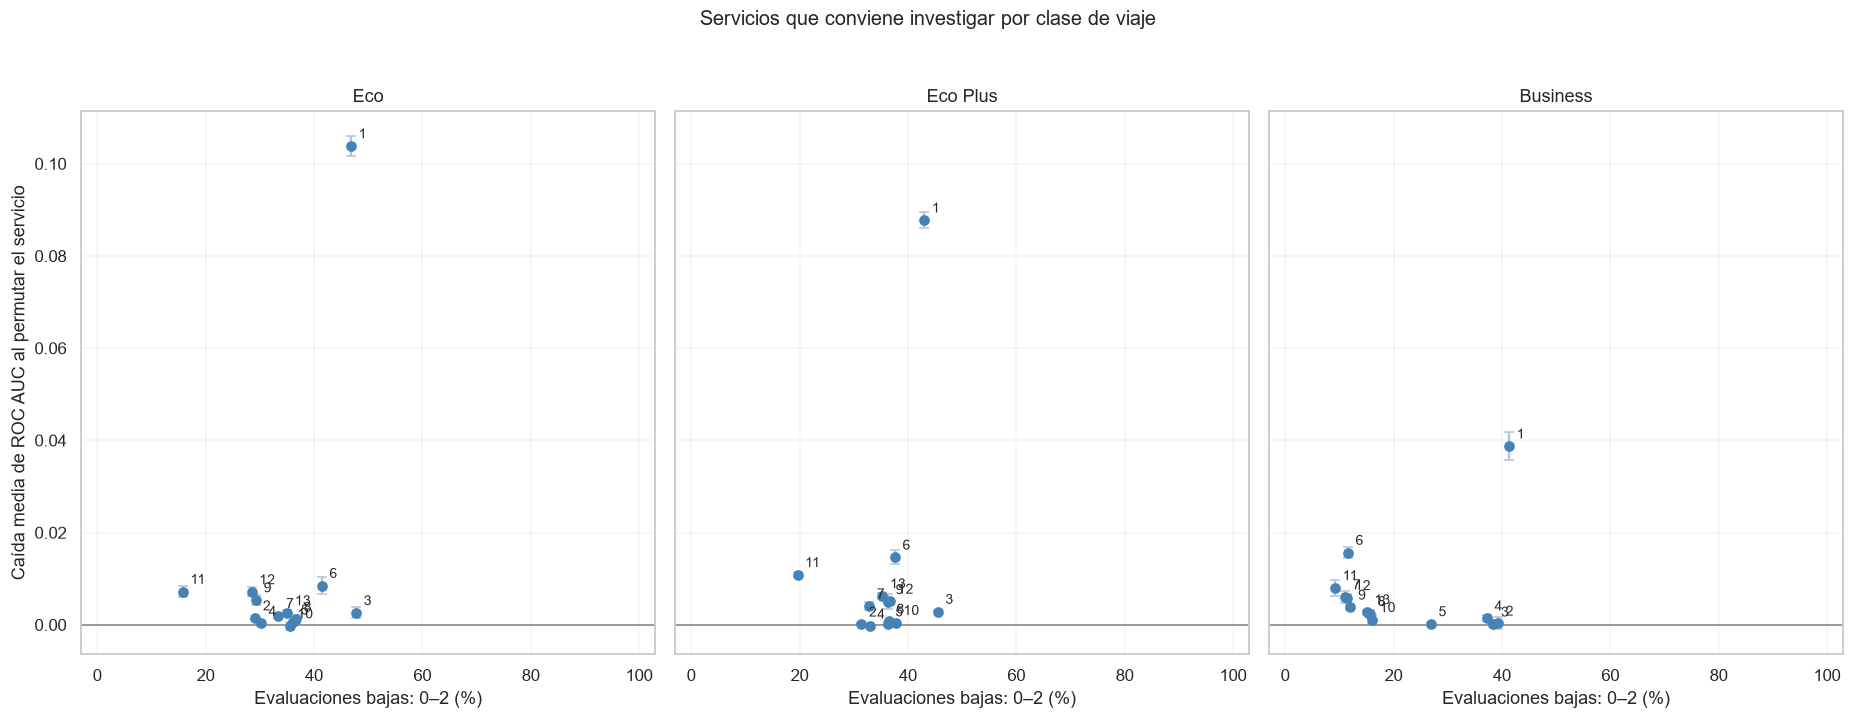

Referencia de los números:
1. Inflight wifi service
2. Departure/Arrival time convenient
3. Ease of Online booking
4. Gate location
5. Food and drink
6. Online boarding
7. Seat comfort
8. Inflight entertainment
9. On-board service
10. Leg room service
11. Baggage handling
12. Checkin service
13. Cleanliness
Eco: candidatos a investigar


,Servicio,Promedio (0–5),Evaluaciones bajas (%),Caída media ROC AUC,Desviación permutaciones
0,Inflight wifi service,2.6451,46.8413,0.1038,0.0022
5,Online boarding,2.8020,41.4423,0.0085,0.0018
12,Cleanliness,3.1112,35.0698,0.0026,0.0006
2,Ease of Online booking,2.6116,47.7857,0.0026,0.0012


Eco Plus: candidatos a investigar


,Servicio,Promedio (0–5),Evaluaciones bajas (%),Caída media ROC AUC,Desviación permutaciones
13,Inflight wifi service,2.7755,43.0179,0.0878,0.0017
18,Online boarding,2.9312,37.5910,0.0146,0.0016
24,Checkin service,2.9692,36.6810,0.0051,0.0006
21,On-board service,2.9897,36.3336,0.0050,0.0016


Business: candidatos a investigar


,Servicio,Promedio (0–5),Evaluaciones bajas (%),Caída media ROC AUC,Desviación permutaciones
26,Inflight wifi service,2.9061,41.3295,0.0387,0.003


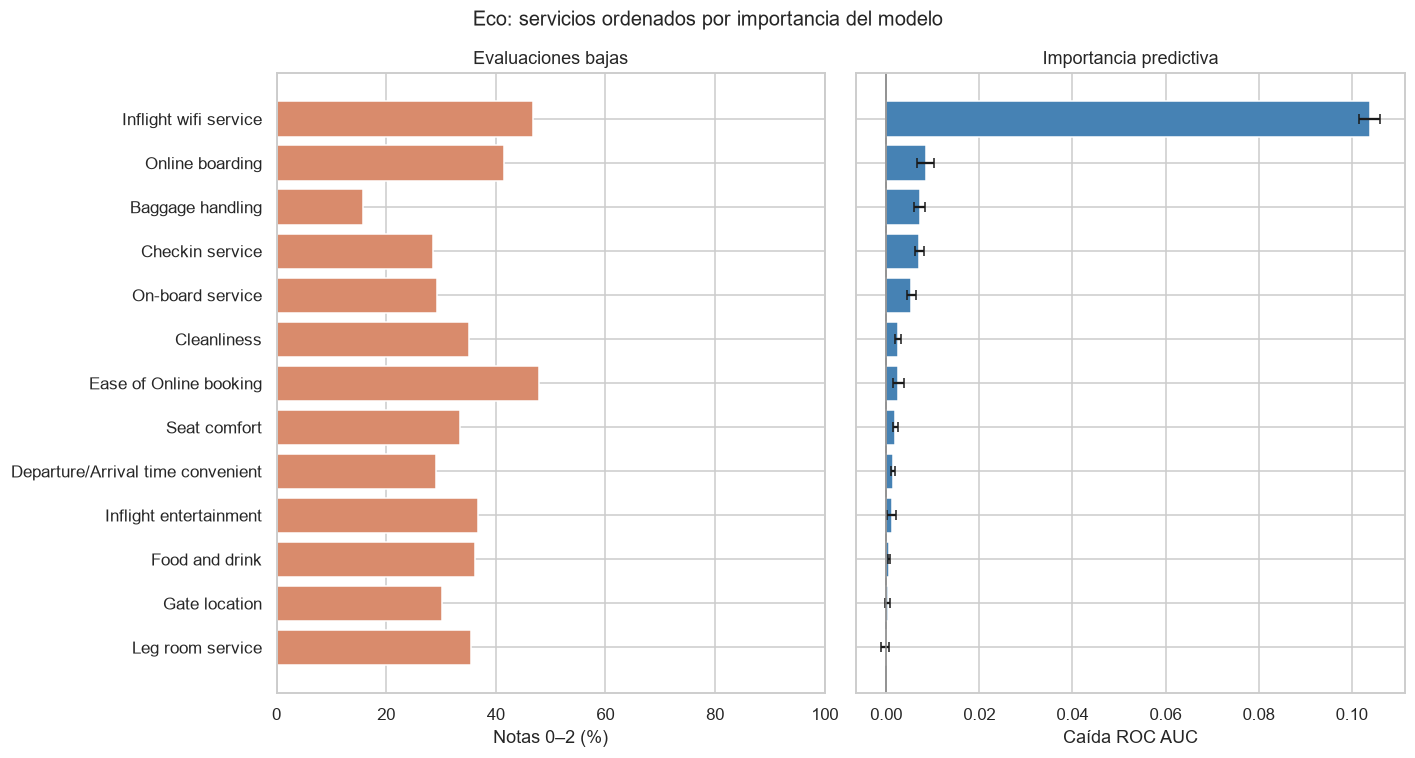

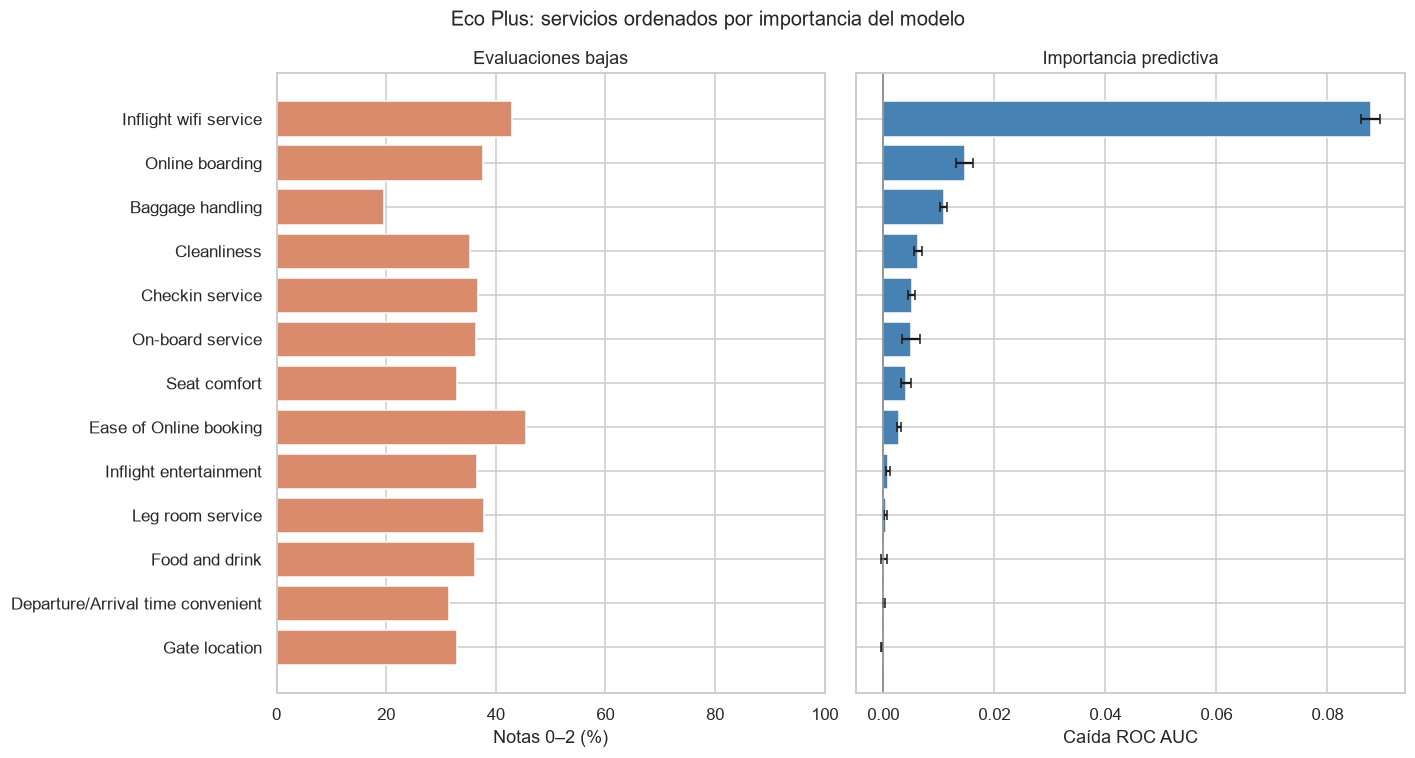

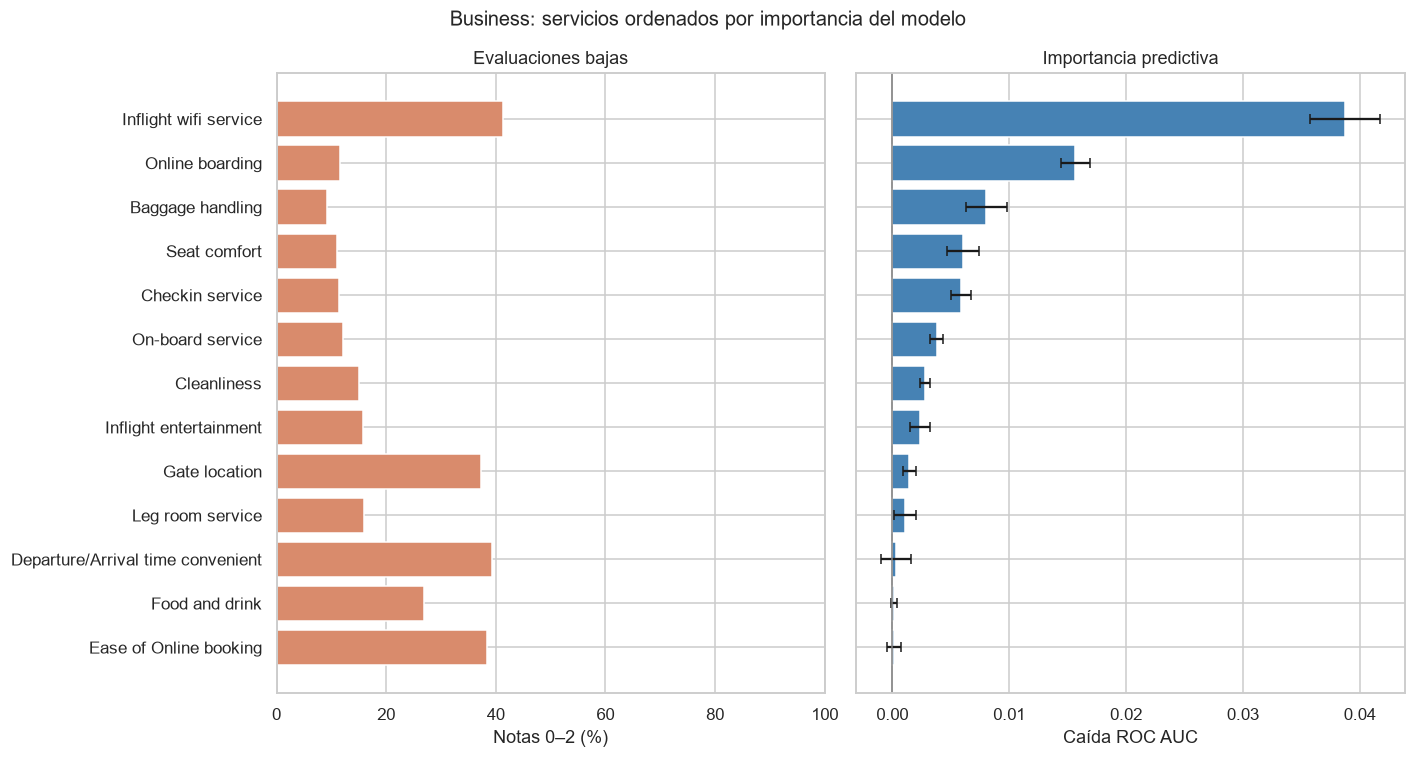

In [25]:
_cell_tag = 'seccion_50'
# 17.3. Derecha = más notas bajas; arriba = mayor importancia predictiva.
fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharex=True, sharey=True)
for ax, clase in zip(axes, clases_analisis):
    datos = prioridades_clase.loc[prioridades_clase['Clase'].eq(clase)]
    if datos.empty:
        ax.text(0.5, 0.5, 'Sin datos suficientes', transform=ax.transAxes, ha='center')
    else:
        ax.errorbar(datos['Evaluaciones bajas (%)'], datos['Caída media ROC AUC'],
                    yerr=datos['Desviación permutaciones'], fmt='o',
                    color='steelblue', ecolor='lightsteelblue', capsize=3)
        for _, fila in datos.iterrows():
            numero = servicios_clase.index(fila['Servicio']) + 1
            ax.annotate(str(numero),
                        (fila['Evaluaciones bajas (%)'], fila['Caída media ROC AUC']),
                        xytext=(5, 5), textcoords='offset points', fontsize=9)
    ax.axhline(0, color='gray', linewidth=1)
    ax.set_title(clase)
    ax.set_xlabel('Evaluaciones bajas: 0–2 (%)')
    ax.set_xlim(-3, 103)
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Caída media de ROC AUC al permutar el servicio')
fig.suptitle('Servicios que conviene investigar por clase de viaje')
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()
print('Referencia de los números:')
for numero, servicio in enumerate(servicios_clase, start=1):
    print(f'{numero}. {servicio}')

# Candidatos: importancia positiva y valores >= mediana de SU segmento
# en ambos ejes. Regla exploratoria, no un umbral de negocio validado.
listas_candidatos = []
for clase in clases_analisis:
    datos = prioridades_clase.loc[prioridades_clase['Clase'].eq(clase)]
    if datos.empty:
        continue
    seleccion = datos.loc[
        datos['Caída media ROC AUC'].gt(0)
        & datos['Caída media ROC AUC'].ge(datos['Caída media ROC AUC'].median())
        & datos['Evaluaciones bajas (%)'].ge(datos['Evaluaciones bajas (%)'].median())
    ].sort_values('Caída media ROC AUC', ascending=False)
    listas_candidatos.append(seleccion)
    print(f'{clase}: candidatos a investigar')
    if seleccion.empty:
        print('Ningún servicio cumple ambos criterios; no se fuerza una prioridad.')
    else:
        display(seleccion[['Servicio', 'Promedio (0–5)', 'Evaluaciones bajas (%)',
                           'Caída media ROC AUC', 'Desviación permutaciones']].round(4))
candidatos_clase = pd.concat(listas_candidatos, ignore_index=True)

# Figuras separadas con nombres completos para las diapositivas.
_cell_tag = 'prioridades_por_clase'
for clase in clases_analisis:
    datos = prioridades_clase.loc[prioridades_clase['Clase'].eq(clase)].sort_values(
        'Caída media ROC AUC', ascending=False)
    if datos.empty:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
    posiciones = np.arange(len(datos))
    axes[0].barh(posiciones, datos['Evaluaciones bajas (%)'], color='#D98B6C')
    axes[0].set_yticks(posiciones, datos['Servicio'])
    axes[0].invert_yaxis()
    axes[0].set(xlim=(0,100), xlabel='Notas 0–2 (%)', title='Evaluaciones bajas')
    axes[1].barh(posiciones, datos['Caída media ROC AUC'],
        xerr=datos['Desviación permutaciones'], color='steelblue', capsize=3)
    axes[1].axvline(0, color='gray', linewidth=1)
    axes[1].set(xlabel='Caída ROC AUC', title='Importancia predictiva')
    fig.suptitle(f'{clase}: servicios ordenados por importancia del modelo')
    fig.tight_layout(); plt.show()


### 17.4. Interpretación y aplicación al negocio

Los servicios **más a la derecha y arriba** combinan muchas notas bajas y alta importancia predictiva: son candidatos a investigar. La tabla aplica una regla transparente: importancia positiva y valores iguales o superiores a las medianas del propio segmento en ambos ejes. Es una selección relativa; las medianas no representan estándares aceptables de servicio. No usamos un puntaje combinado que esconda las métricas.

- Las barras de error muestran desviación entre cinco permutaciones, **no intervalos de confianza**. No incluyen toda la incertidumbre del muestreo o entrenamiento.
- Las evaluaciones descriptivas usan toda la validación; las importancias usan hasta 5.000 registros por clase. La tabla de diagnóstico informa sus tamaños y desempeños.
- Una importancia cercana a cero no implica que el servicio no importe a los pasajeros: otras variables pueden aportar información similar. Una importancia negativa puede reflejar variabilidad o información poco útil para el modelo.
- La importancia no indica dirección del efecto. Los tamaños y distribuciones de los grupos difieren; una diferencia entre clases no demuestra por sí sola diferencias de preferencias.
- Caída de ROC AUC no significa caída de satisfacción ni retorno económico. El análisis utiliza información posterior al viaje y no demuestra causalidad.

**Idea de negocio, en simple:** ofrecer un diagnóstico periódico que ayude a una aerolínea a investigar oportunidades de mejora específicas para Eco, Eco Plus y Business. Se partiría de estos resultados y se contrastarían con comentarios de pasajeros, costos y factibilidad.

Para comprobar una mejora, habría que realizar un piloto con una comparación adecuada y medir su efecto. El dataset de Kaggle sirve como demostración; las conclusiones deben validarse con datos reales antes de recomendar inversiones.


## 18. Errores del modelo por clase

La clase positiva es satisfecho. Un falso positivo es un pasajero no satisfecho clasificado como satisfecho (problema potencialmente inadvertido); un falso negativo es un satisfecho clasificado como no satisfecho (posible revisión innecesaria). Los costos dependen de la decisión posterior. No tenemos montos observados para asignarles dinero.


,Clase,N,TN,FP,FN,TP,Error (%),No satisfechos inadvertidos (%),Satisfechos con falsa alerta (%)
0,Eco,65438,53502,979,4343,6614,8.13,1.80,39.64
1,Eco Plus,6044,4443,138,411,1052,9.08,3.01,28.09
2,Business,68445,15392,3405,1380,48268,6.99,18.11,2.78


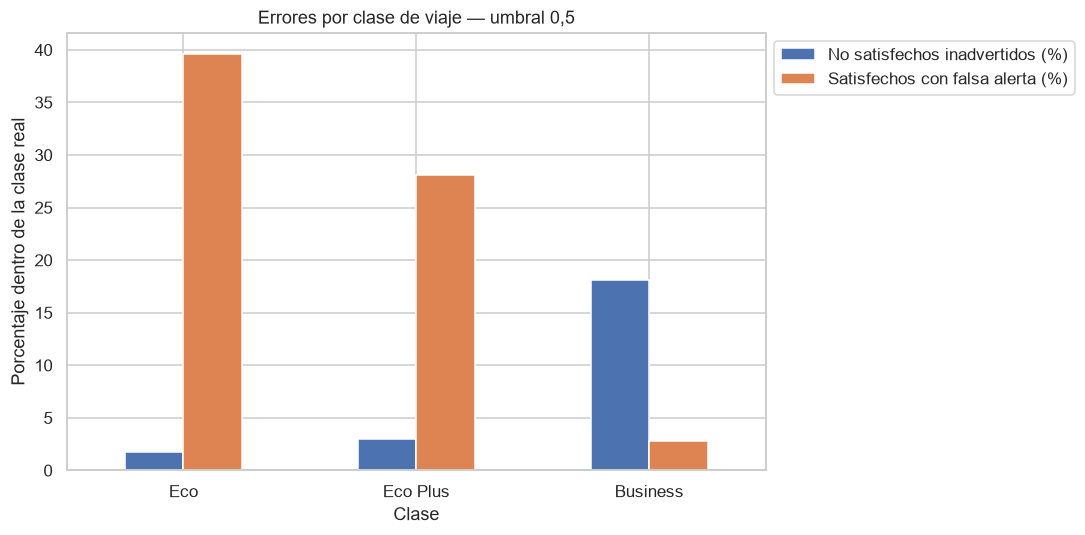

In [26]:
_cell_tag = 'seccion_53'
from sklearn.metrics import confusion_matrix
pred_val = prob_validacion[mejor_nombre] >= 0.5
filas_errores = []
for clase in clases_analisis:
    mascara = X_val['Class'].eq(clase).to_numpy()
    real, pred = y_val.iloc[np.flatnonzero(mascara)], pred_val[mascara]
    tn, fp, fn, tp = confusion_matrix(real, pred, labels=[0, 1]).ravel()
    filas_errores.append({'Clase': clase, 'N': len(real), 'TN': tn, 'FP': fp,
        'FN': fn, 'TP': tp, 'Error (%)': 100 * (fp+fn)/len(real),
        'No satisfechos inadvertidos (%)': 100*fp/(tn+fp) if tn+fp else np.nan,
        'Satisfechos con falsa alerta (%)': 100*fn/(tp+fn) if tp+fn else np.nan})
errores_clase = pd.DataFrame(filas_errores)
display(errores_clase.round(2))
ax = errores_clase.set_index('Clase')[['No satisfechos inadvertidos (%)',
    'Satisfechos con falsa alerta (%)']].plot.bar(figsize=(10,5), rot=0)
ax.set(ylabel='Porcentaje dentro de la clase real', title='Errores por clase de viaje — umbral 0,5')
ax.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()


## 19. SHAP: explicación global y de un caso concreto

Explicamos el **HistGradientBoosting** ajustado solo con X_fit, aunque otro modelo resultara ganador al repetir la ejecución. Se indica explícitamente su desempeño. El preprocesamiento es exactamente el del pipeline entrenado. Usamos TreeExplainer en modo tree_path_dependent y salida raw: las contribuciones están en **log-odds de satisfacción**, no en puntos porcentuales.

La muestra global contiene hasta 1.000 pasajeros de validación, estratificados por clase de viaje y satisfacción con semilla 42. El beeswarm muestra variables transformadas: las categorías one-hot son indicadores 0/1, no escalas ordinales. Para comparar columnas originales, sumamos las contribuciones firmadas de sus indicadores por pasajero y luego calculamos el promedio absoluto. Esto es una agregación descriptiva de las atribuciones transformadas.

Para el caso local elegimos reproduciblemente el primer falso positivo por índice original; si no existe, el primer error y, si no hay errores, el primer registro. No seleccionamos el ejemplo para lograr una explicación conveniente. SHAP explica el modelo, no causas ni beneficios de intervenciones.

Referencia técnica: [TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).


c:\Users\agust\OneDrive\Escritorio\Repositorio_PdD2\proy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo SHAP: Gradient boosting; ganador por AUC: Gradient boosting
AUC de Gradient boosting en validación: 0.9570147022132287
Muestra SHAP: 1000 | unidad: log-odds de satisfacción


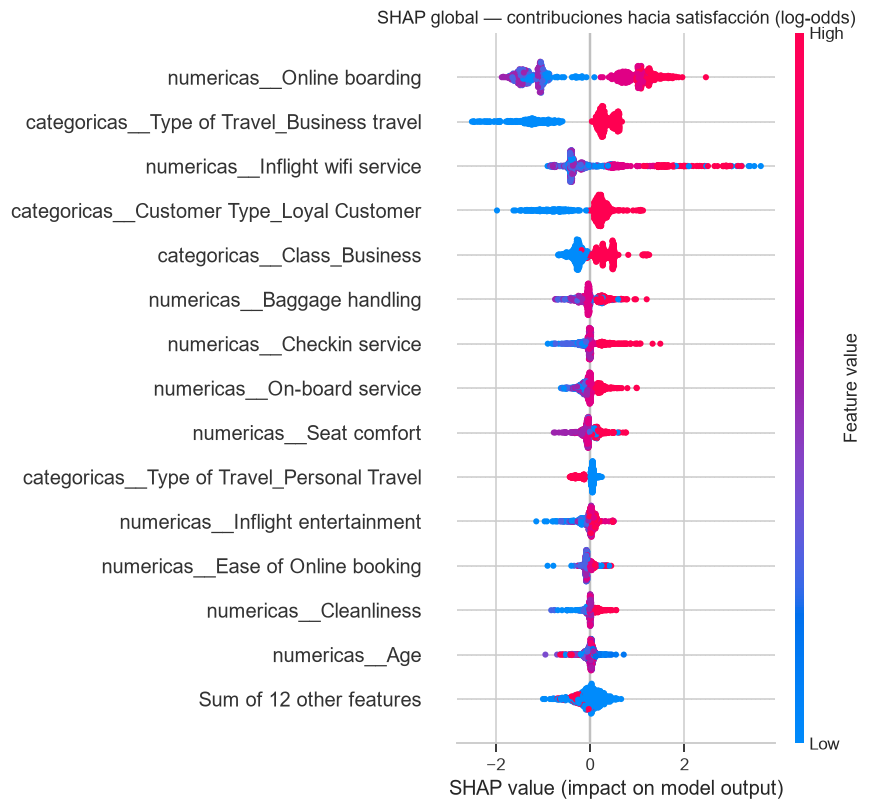

,Media |SHAP| (log-odds)
Online boarding,1.131771
Type of Travel,0.726346
Inflight wifi service,0.611443
Customer Type,0.417207
Class,0.298291
Baggage handling,0.177412
Checkin service,0.137809
On-board service,0.135110
Seat comfort,0.120183
Inflight entertainment,0.099889


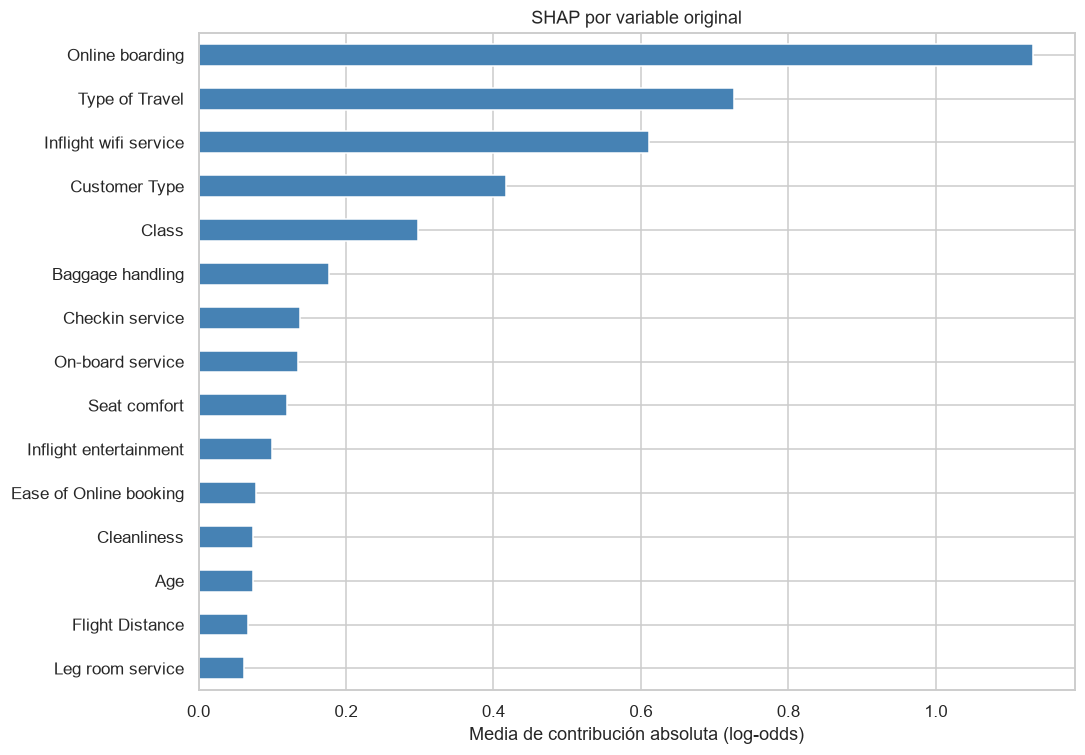

In [27]:
_cell_tag = 'seccion_55'
import shap
from scipy.special import expit
pipe_shap = modelos['Gradient boosting']
modelo_shap = pipe_shap.named_steps['modelo']
prep_shap = pipe_shap.named_steps['preparar']
estratos_shap = X_val['Class'].astype(str) + '_' + y_val.astype(str)
if len(X_val) > 1_000:
    X_shap, _, y_shap, _ = train_test_split(X_val, y_val, train_size=1_000,
        stratify=estratos_shap, random_state=42)
else:
    X_shap, y_shap = X_val.copy(), y_val.copy()
Z_shap = prep_shap.transform(X_shap)
nombres_shap = prep_shap.get_feature_names_out()
explainer = shap.TreeExplainer(modelo_shap, model_output='raw',
    feature_perturbation='tree_path_dependent', feature_names=list(nombres_shap))
exp_shap = explainer(Z_shap, check_additivity=True)
assert np.allclose(expit(exp_shap.base_values + exp_shap.values.sum(axis=1)),
    pipe_shap.predict_proba(X_shap)[:, 1], atol=1e-6)
print('Modelo SHAP: Gradient boosting; ganador por AUC:', mejor_nombre)
print('AUC de Gradient boosting en validación:',
    roc_auc_score(y_val, prob_validacion['Gradient boosting']))
print('Muestra SHAP:', len(X_shap), '| unidad: log-odds de satisfacción')
shap.plots.beeswarm(exp_shap, max_display=15, show=False)
plt.title('SHAP global — contribuciones hacia satisfacción (log-odds)')
plt.tight_layout(); plt.show()

# Mapa exacto del orden del ColumnTransformer y del OneHotEncoder.
originales_shap = list(num_modelo)
ohe = prep_shap.named_transformers_['categoricas'].named_steps['onehot']
for columna, categorias in zip(cat_modelo, ohe.categories_):
    originales_shap.extend([columna] * len(categorias))
assert len(originales_shap) == exp_shap.values.shape[1]
shap_original = pd.DataFrame(exp_shap.values, columns=originales_shap,
    index=X_shap.index).T.groupby(level=0, sort=False).sum().T
ranking_shap = shap_original.abs().mean().sort_values(ascending=False)
display(ranking_shap.to_frame('Media |SHAP| (log-odds)'))
ax = ranking_shap.head(15).sort_values().plot.barh(figsize=(10,7), color='steelblue')
ax.set(title='SHAP por variable original', xlabel='Media de contribución absoluta (log-odds)')
plt.tight_layout(); plt.show()


Registro 16; clase: Eco
Real: 0; P(satisfecho): 0.631; predicción: 1
Base SHAP: -0.438 log-odds; no es probabilidad promedio.


,Valor observado
Age,23
Flight Distance,588
Inflight wifi service,4
Departure/Arrival time convenient,0
Ease of Online booking,4
Gate location,1
Food and drink,3
Online boarding,4
Seat comfort,3
Inflight entertainment,3


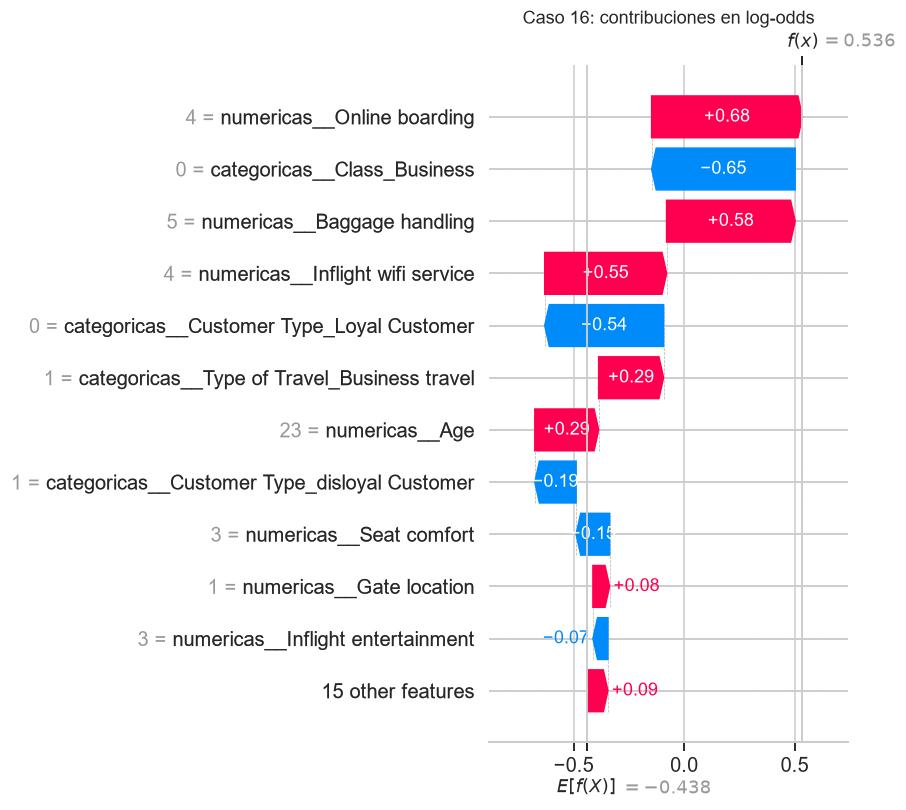

,Variable transformada,Valor transformado,Contribución SHAP
15,numericas__Online boarding,4.0,0.682798
23,categoricas__Class_Business,0.0,-0.649550
2,numericas__Baggage handling,5.0,0.581869
12,numericas__Inflight wifi service,4.0,0.551561
19,categoricas__Customer Type_Loyal Customer,0.0,-0.537761
21,categoricas__Type of Travel_Business travel,1.0,0.293629
0,numericas__Age,23.0,0.289057
20,categoricas__Customer Type_disloyal Customer,1.0,-0.186825
16,numericas__Seat comfort,3.0,-0.151677
10,numericas__Gate location,1.0,0.075470


Contribuciones positivas empujan hacia satisfecho; negativas hacia no satisfecho.
La explicación muestra por qué se produce la predicción, no justifica su corrección.


**Lectura del caso:** las contribuciones que más empujan hacia satisfecho son numericas__Online boarding, numericas__Baggage handling, numericas__Inflight wifi service; las que más empujan en sentido contrario son categoricas__Class_Business, categoricas__Customer Type_Loyal Customer, categoricas__Customer Type_disloyal Customer. Esta lectura corresponde a este pasajero y modelo.

In [28]:
_cell_tag = 'seccion_56'
p_gb = pd.Series(prob_validacion['Gradient boosting'], index=X_val.index)
fp_idx = y_val.index[y_val.eq(0) & p_gb.ge(0.5)]
error_idx = y_val.index[y_val.ne(p_gb.ge(0.5).astype(int))]
pool = fp_idx if len(fp_idx) else error_idx if len(error_idx) else X_val.index
indice_caso = sorted(pool)[0]
X_caso = X_val.loc[[indice_caso]]
exp_caso = explainer(prep_shap.transform(X_caso), check_additivity=True)
p_caso = float(p_gb.loc[indice_caso])
assert np.isclose(expit(exp_caso.base_values[0] + exp_caso.values[0].sum()), p_caso)
print(f'Registro {indice_caso}; clase: {X_caso.iloc[0]["Class"]}')
print(f'Real: {int(y_val.loc[indice_caso])}; P(satisfecho): {p_caso:.3f}; predicción: {int(p_caso>=0.5)}')
print(f'Base SHAP: {exp_caso.base_values[0]:.3f} log-odds; no es probabilidad promedio.')
display(X_caso.T.rename(columns={indice_caso: 'Valor observado'}))
shap.plots.waterfall(exp_caso[0], max_display=12, show=False)
plt.title(f'Caso {indice_caso}: contribuciones en log-odds')
plt.tight_layout(); plt.show()
contrib_caso = pd.DataFrame({'Variable transformada': nombres_shap,
    'Valor transformado': prep_shap.transform(X_caso)[0],
    'Contribución SHAP': exp_caso.values[0]})
display(contrib_caso.reindex(contrib_caso['Contribución SHAP'].abs()
    .sort_values(ascending=False).index).head(10))
print('Contribuciones positivas empujan hacia satisfecho; negativas hacia no satisfecho.')
print('La explicación muestra por qué se produce la predicción, no justifica su corrección.')

from IPython.display import Markdown
positivas = contrib_caso.loc[contrib_caso['Contribución SHAP'].gt(0)].nlargest(3, 'Contribución SHAP')
negativas = contrib_caso.loc[contrib_caso['Contribución SHAP'].lt(0)].nsmallest(3, 'Contribución SHAP')
display(Markdown('**Lectura del caso:** las contribuciones que más empujan hacia satisfecho son ' +
    ', '.join(positivas['Variable transformada']) + '; las que más empujan en sentido contrario son ' +
    ', '.join(negativas['Variable transformada']) + '. Esta lectura corresponde a este pasajero y modelo.'))


## 20. Recomendación y límites

El equipo de experiencia del cliente puede usar el diagnóstico para revisar **hasta dos servicios por clase** entre los candidatos de la sección 17; esta capacidad es una propuesta de trabajo, no un umbral optimizado. La decisión final debe incorporar comentarios de pasajeros, costo y factibilidad. Un servicio importante con buena evaluación puede requerir mantener el estándar, no intervenir.

El costo de usar el sistema incluye preparación de encuestas, ejecución periódica y tiempo del analista. Los errores de clasificación podrían generar revisiones innecesarias o dejar problemas inadvertidos si se usan para triaje individual; el uso principal propuesto es diagnóstico agregado. No aplicamos automáticamente compensaciones ni intervenciones a pasajeros.

No se dispone de costos de intervención ni de un efecto causal estimado. Como escenario explícito, el beneficio neto de un piloto sería: beneficio atribuible a la mejora menos costo de implementación, operación y evaluación. Sin medir esos términos no prometemos ahorros. El siguiente paso es un piloto con comparación adecuada y un indicador acordado de satisfacción, junto a costos y quejas.

Limitaciones: datos de competición, análisis exploratorio previo sobre todo train, selección de modelos con la misma validación, importancias sensibles a correlaciones, ausencia de evaluación externa y uso de datos posteriores al viaje. Una evaluación cruzada dentro del entrenamiento puede medir estabilidad; no se afirma que esté realizada. La escala de servicios se usa según la definición confirmada por el equipo.


In [29]:
_cell_tag = 'seccion_58'
from IPython.display import Markdown
ganador = comparacion.loc[comparacion['Modelo'].isin(modelos)].iloc[0]
display(Markdown(f"**Resultado técnico:** {ganador['Modelo']} obtuvo ROC AUC "
    f"{ganador['ROC AUC']:.5f} y accuracy {ganador['Accuracy']:.2%}. "
    "Supera la referencia constante en esta validación; esto no acredita utilidad comercial."))
display(Markdown('**Variables con mayor contribución global SHAP:** ' +
    ', '.join(ranking_shap.head(5).index) + '.'))
for clase in clases_analisis:
    candidatos = candidatos_clase.loc[candidatos_clase['Clase'].eq(clase)].head(2)
    nombres = ', '.join(candidatos['Servicio']) if len(candidatos) else 'sin candidatos según la regla'
    display(Markdown(f'**{clase}:** investigar {nombres}. No constituye evidencia causal.'))
for nombre, tabla in {'comparacion_modelos': comparacion, 'errores_clase': errores_clase,
    'prioridades_clase': prioridades_clase, 'candidatos_clase': candidatos_clase,
    'shap_importancia_global': ranking_shap.to_frame('Media |SHAP|'),
    'shap_caso': contrib_caso}.items():
    tabla.to_csv(OUTPUT_DIR / f'{nombre}.csv', index=True)
import importlib.metadata as md
versiones = {p: md.version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','shap']}
display(versiones)
Path('versiones_ejecucion.json').write_text(__import__('json').dumps(versiones, indent=2))
print('Figuras exportadas en PNG y SVG:', FIG_DIR.resolve())


**Resultado técnico:** Gradient boosting obtuvo ROC AUC 0.95701 y accuracy 92.38%. Supera la referencia constante en esta validación; esto no acredita utilidad comercial.

**Variables con mayor contribución global SHAP:** Online boarding, Type of Travel, Inflight wifi service, Customer Type, Class.

**Eco:** investigar Inflight wifi service, Online boarding. No constituye evidencia causal.

**Eco Plus:** investigar Inflight wifi service, Online boarding. No constituye evidencia causal.

**Business:** investigar Inflight wifi service. No constituye evidencia causal.

{'numpy': '2.5.2',
 'pandas': '3.0.5',
 'scikit-learn': '1.9.0',
 'matplotlib': '3.11.1',
 'shap': '0.54.1'}

Figuras exportadas en PNG y SVG: C:\Users\agust\OneDrive\Escritorio\Repositorio_PdD2\proy\figuras_presentacion
